### Finding out the Checkpoints to Download for Testing

In [22]:
import pandas as pd
import numpy as np
import os
import re

DIR = os.environ.get("RBC_DIR", os.path.abspath("."))
FIGURES_DIR = r"Figures"

LOO_SPLITS = {
    "LOO_BHRC": "BHRC",
    "LOO_CCNP": "CCNP",
    "LOO_HBN":  "HBN",
    "LOO_NKI":  "NKI",
    "LOO_PNC":  "PNC",
}

TOP_K = 5

In [23]:
def arch_group(row):
    """One of the canonical groups (see GROUPS) based on trial_id suffix + degree_norm."""
    m = re.search(r'_(gcn|gat)_(fmri|multi|concat)$', row["trial_id"])
    if m is None:
        return "unknown"
    arch = m.group(1).upper()
    mod  = {"fmri": "fMRI", "multi": "fMRI&sMRI", "concat": "fMRI_concat_sMRI"}[m.group(2)]
    deg  = str(row["degree_norm"]).strip().lower() in ("true", "1")
    return f"{arch}_{mod}" + ("" if deg or arch == "GAT" else "_nodeg")


all_dfs = {}
for split, test_study in LOO_SPLITS.items():
    df = pd.read_csv(os.path.join(DIR, split, "results_table.csv"))
    df["arch_group"] = df.apply(arch_group, axis=1)
    all_dfs[split] = df
    print(f"{split}: {len(df)} trials")
    print(df["arch_group"].value_counts().to_string(), "\n")

LOO_BHRC: 3645 trials
arch_group
GAT_fMRI                      729
GAT_fMRI&sMRI                 729
GAT_fMRI_concat_sMRI          729
GCN_fMRI                      243
GCN_fMRI&sMRI                 243
GCN_fMRI_nodeg                243
GCN_fMRI&sMRI_nodeg           243
GCN_fMRI_concat_sMRI          243
GCN_fMRI_concat_sMRI_nodeg    243 

LOO_CCNP: 3645 trials
arch_group
GAT_fMRI&sMRI                 729
GAT_fMRI                      729
GAT_fMRI_concat_sMRI          729
GCN_fMRI                      243
GCN_fMRI&sMRI                 243
GCN_fMRI_nodeg                243
GCN_fMRI&sMRI_nodeg           243
GCN_fMRI_concat_sMRI          243
GCN_fMRI_concat_sMRI_nodeg    243 

LOO_HBN: 3645 trials
arch_group
GAT_fMRI&sMRI                 729
GAT_fMRI                      729
GAT_fMRI_concat_sMRI          729
GCN_fMRI                      243
GCN_fMRI&sMRI                 243
GCN_fMRI_nodeg                243
GCN_fMRI&sMRI_nodeg           243
GCN_fMRI_concat_sMRI          243
GCN_fMRI_conca

In [24]:
GROUPS = [
    "GCN_fMRI",
    "GCN_fMRI_nodeg",
    "GCN_fMRI&sMRI",
    "GCN_fMRI&sMRI_nodeg",
    "GAT_fMRI",
    "GAT_fMRI&sMRI",
    "GCN_fMRI_concat_sMRI",
    "GCN_fMRI_concat_sMRI_nodeg",
    "GAT_fMRI_concat_sMRI",
]

COLS = ["trial_id", "best_state_val_loss", "best_val_r", "best_val_mae", "fc_processing", "lr", "weight_decay"]

top_k = {}  # top_k[split][group] = DataFrame

for split, df in all_dfs.items():
    top_k[split] = {}
    for group in GROUPS:
        sub = (
            df[df["arch_group"] == group]
            .nlargest(TOP_K, "best_val_r")[COLS]
            .reset_index(drop=True)
        )
        top_k[split][group] = sub

# Display
for split, test_study in LOO_SPLITS.items():
    print(f"\n{'='*72}")
    print(f"  {split}  (test: {test_study})")
    print(f"{'='*72}")
    for group in GROUPS:
        sub = top_k[split][group]
        print(f"\n  [{group}]  (n={len(sub)})")
        print(sub.to_string(index=True))


  LOO_BHRC  (test: BHRC)

  [GCN_fMRI]  (n=5)
                        trial_id  best_state_val_loss  best_val_r  best_val_mae fc_processing     lr  weight_decay
0   trial_1.32.2.1.3.10_gcn_fmri             0.013856       0.743         2.054        per_10  0.010       0.00001
1  trial_1.128.3.1.3.20_gcn_fmri             0.014591       0.733         2.096        per_20  0.010       0.00001
2   trial_1.64.2.1.3.10_gcn_fmri             0.014602       0.731         2.143        per_10  0.010       0.00001
3   trial_1.32.2.2.2.20_gcn_fmri             0.014535       0.731         2.130        per_20  0.001       0.00010
4  trial_1.128.3.1.3.10_gcn_fmri             0.015737       0.728         2.190        per_10  0.010       0.00001

  [GCN_fMRI_nodeg]  (n=5)
                              trial_id  best_state_val_loss  best_val_r  best_val_mae fc_processing     lr  weight_decay
0   trial_1_nodeg.32.2.1.3.10_gcn_fmri             0.013243       0.746         2.018        per_10  0.010       0.

In [25]:
print("# ===== DOWNLOAD MANIFEST =====")
print(f"# Top-{TOP_K} per architecture per split  (ranked by best_state_val_loss ↑)")
print("# Files needed per trial: config.json  +  ckpt/best_model.pth\n")

all_trial_ids = []

for split, test_study in LOO_SPLITS.items():
    print(f"# --- {split} (test={test_study}) ---")
    for group in GROUPS:
        ids = top_k[split][group]["trial_id"].tolist()
        for tid in ids:
            loss = top_k[split][group].loc[top_k[split][group]["trial_id"] == tid, "best_state_val_loss"].values[0]
            print(f"{tid}  # {group}  val_loss={loss:.5f}")
            all_trial_ids.append(tid)
    print()

print(f"# Total: {len(all_trial_ids)} trials  ({len(set(all_trial_ids))} unique)")

# ===== DOWNLOAD MANIFEST =====
# Top-5 per architecture per split  (ranked by best_state_val_loss ↑)
# Files needed per trial: config.json  +  ckpt/best_model.pth

# --- LOO_BHRC (test=BHRC) ---
trial_1.32.2.1.3.10_gcn_fmri  # GCN_fMRI  val_loss=0.01386
trial_1.128.3.1.3.20_gcn_fmri  # GCN_fMRI  val_loss=0.01459
trial_1.64.2.1.3.10_gcn_fmri  # GCN_fMRI  val_loss=0.01460
trial_1.32.2.2.2.20_gcn_fmri  # GCN_fMRI  val_loss=0.01454
trial_1.128.3.1.3.10_gcn_fmri  # GCN_fMRI  val_loss=0.01574
trial_1_nodeg.32.2.1.3.10_gcn_fmri  # GCN_fMRI_nodeg  val_loss=0.01324
trial_1_nodeg.128.2.2.2.10_gcn_fmri  # GCN_fMRI_nodeg  val_loss=0.01353
trial_1_nodeg.32.3.1.2.50_gcn_fmri  # GCN_fMRI_nodeg  val_loss=0.01379
trial_1_nodeg.64.2.1.3.10_gcn_fmri  # GCN_fMRI_nodeg  val_loss=0.01446
trial_1_nodeg.128.1.2.2.10_gcn_fmri  # GCN_fMRI_nodeg  val_loss=0.01402
trial_2.8.2.1.3.20_gcn_multi  # GCN_fMRI&sMRI  val_loss=0.01146
trial_2.64.3.2.3.10_gcn_multi  # GCN_fMRI&sMRI  val_loss=0.01175
trial_2.16.2.2.2.50_g

### Load the test_results and merge with the top-k trials

In [26]:
def arch_group_test(row):
    """One of the canonical groups (see GROUPS) based on trial_id suffix + degree_norm."""
    m = re.search(r'_(gcn|gat)_(fmri|multi|concat)$', row["trial_id"])
    if m is None:
        return "unknown"
    arch = m.group(1).upper()
    mod  = {"fmri": "fMRI", "multi": "fMRI&sMRI", "concat": "fMRI_concat_sMRI"}[m.group(2)]
    deg  = not any(el.startswith("nodeg") for el in row["trial_id"].split("_"))
    return f"{arch}_{mod}" + ("" if deg or arch == "GAT" else "_nodeg")


for split, test_study in LOO_SPLITS.items():
    test_res = pd.read_csv(f"{DIR}/LOO_{test_study}/test_results.csv")
    test_res["arch_group"] = test_res.apply(arch_group_test, axis=1)
    for group in GROUPS:
        test_res_temp = test_res[test_res["arch_group"] == group].copy()
        top_k[split][group] = (
            top_k[split][group]
            .merge(test_res_temp, on="trial_id", how="left")
            .drop(columns=["train_datasets", "test_datasets", "arch_group"], errors="ignore")
        )

### Tabulating the Results

In [27]:
print(GROUPS)

['GCN_fMRI', 'GCN_fMRI_nodeg', 'GCN_fMRI&sMRI', 'GCN_fMRI&sMRI_nodeg', 'GAT_fMRI', 'GAT_fMRI&sMRI', 'GCN_fMRI_concat_sMRI', 'GCN_fMRI_concat_sMRI_nodeg', 'GAT_fMRI_concat_sMRI']


In [28]:
from IPython.display import display


for split, test_study in LOO_SPLITS.items():
    print(split)
    display(top_k[split]["GCN_fMRI"].head())

LOO_BHRC


,trial_id,best_state_val_loss,best_val_r,best_val_mae,fc_processing,lr,weight_decay,test_r,test_r2,test_mae,test_mse
0,trial_1.32.2.1.3.10_gcn_fmri,0.013856,0.743,2.054,per_10,0.010,0.00001,0.3976,-0.5707,1.8530,4.9554
1,trial_1.128.3.1.3.20_gcn_fmri,0.014591,0.733,2.096,per_20,0.010,0.00001,0.3215,-2.1463,2.6084,9.9265
2,trial_1.64.2.1.3.10_gcn_fmri,0.014602,0.731,2.143,per_10,0.010,0.00001,0.4029,-1.3183,2.3121,7.3140
3,trial_1.32.2.2.2.20_gcn_fmri,0.014535,0.731,2.130,per_20,0.001,0.00010,0.1464,-0.2071,1.6169,3.8084
4,trial_1.128.3.1.3.10_gcn_fmri,0.015737,0.728,2.190,per_10,0.010,0.00001,0.3837,-1.7030,2.4926,8.5277


LOO_CCNP


,trial_id,best_state_val_loss,best_val_r,best_val_mae,fc_processing,lr,weight_decay,test_r,test_r2,test_mae,test_mse
0,trial_1.64.3.1.3.10_gcn_fmri,0.011378,0.806,1.874,per_10,0.010,0.00001,0.0854,-0.3073,2.9141,12.9582
1,trial_1.128.1.3.2.10_gcn_fmri,0.011739,0.797,1.903,per_10,0.001,0.00100,0.0276,-0.4238,3.0750,14.1125
2,trial_1.32.3.1.3.10_gcn_fmri,0.011989,0.790,1.913,per_10,0.010,0.00001,0.0341,-0.2586,2.8666,12.4754
3,trial_1.32.3.2.2.10_gcn_fmri,0.012026,0.790,1.924,per_10,0.001,0.00010,0.0663,-0.1942,2.8310,11.8375
4,trial_1.64.3.1.2.10_gcn_fmri,0.013693,0.783,2.129,per_10,0.001,0.00001,0.0216,-0.1800,2.8447,11.6964


LOO_HBN


,trial_id,best_state_val_loss,best_val_r,best_val_mae,fc_processing,lr,weight_decay,test_r,test_r2,test_mae,test_mse
0,trial_1.64.3.1.2.20_gcn_fmri,0.014800,0.726,2.155,per_20,0.001,0.00001,0.6073,-0.0907,2.8185,13.4420
1,trial_1.32.3.2.3.10_gcn_fmri,0.015191,0.712,2.168,per_10,0.010,0.00010,0.6681,0.2668,2.3839,9.0363
2,trial_1.64.2.1.3.20_gcn_fmri,0.016236,0.712,2.162,per_20,0.010,0.00001,0.5179,-0.5555,3.4754,19.1701
3,trial_1.32.3.1.2.10_gcn_fmri,0.015411,0.708,2.168,per_10,0.001,0.00001,0.7235,0.4817,2.0143,6.3872
4,trial_1.32.3.2.3.20_gcn_fmri,0.017028,0.708,2.343,per_20,0.010,0.00010,0.6625,0.3720,2.2444,7.7402


LOO_NKI


,trial_id,best_state_val_loss,best_val_r,best_val_mae,fc_processing,lr,weight_decay,test_r,test_r2,test_mae,test_mse
0,trial_1.128.2.1.3.10_gcn_fmri,0.015131,0.735,2.124,per_10,0.0100,0.00001,0.7584,0.0480,2.6327,10.5093
1,trial_1.128.3.1.3.10_gcn_fmri,0.014301,0.735,2.043,per_10,0.0100,0.00001,0.7618,-0.0511,2.9070,11.6025
2,trial_1.128.2.2.3.10_gcn_fmri,0.017108,0.716,2.283,per_10,0.0100,0.00010,0.7576,0.1303,2.5281,9.6004
3,trial_1.128.2.3.1.50_gcn_fmri,0.015151,0.711,2.152,per_50,0.0001,0.00100,0.7212,-1.5197,4.7391,27.8146
4,trial_1.64.2.1.3.10_gcn_fmri,0.015696,0.710,2.274,per_10,0.0100,0.00001,0.7632,0.5539,1.7285,4.9242


LOO_PNC


,trial_id,best_state_val_loss,best_val_r,best_val_mae,fc_processing,lr,weight_decay,test_r,test_r2,test_mae,test_mse
0,trial_1.32.1.2.2.10_gcn_fmri,0.009735,0.770,1.701,per_10,0.001,0.00010,0.3198,-2.7082,5.7933,43.4712
1,trial_1.64.3.2.2.10_gcn_fmri,0.011060,0.769,1.932,per_10,0.001,0.00010,0.1831,-1.1388,4.1997,25.0735
2,trial_1.32.3.1.2.20_gcn_fmri,0.009679,0.768,1.686,per_20,0.001,0.00001,0.1828,-1.0767,4.1178,24.3450
3,trial_1.32.3.1.2.10_gcn_fmri,0.009950,0.761,1.717,per_10,0.001,0.00001,0.2810,-1.9840,5.0658,34.9810
4,trial_1.32.1.2.2.20_gcn_fmri,0.009900,0.761,1.735,per_20,0.001,0.00010,0.1954,-1.6058,4.6813,30.5477


In [29]:
DISPLAY_COLS = ["trial_id", "fc_processing", "lr", "weight_decay",
                "best_val_r", "best_val_mae", "test_r", "test_mae"]

def show_group(group):
    print(f"\n{'#'*72}")
    print(f"  {group}")
    print(f"{'#'*72}")
    for split, test_study in LOO_SPLITS.items():
        df = top_k[split][group].copy()
        print(f"\n  {split}  (test: {test_study})")
        cols = [c for c in DISPLAY_COLS if c in df.columns]
        display(df[cols].style.format({
            "lr":           "{:.0e}",
            "weight_decay": "{:.0e}",
            "best_val_r":   "{:.3f}",
            "best_val_mae": "{:.2f}",
            "test_r":       "{:.3f}",
            "test_mae":     "{:.2f}",
        }).hide(axis="index"))

        r_val    = df["best_val_r"].dropna()
        mae_val  = df["best_val_mae"].dropna()
        r_test   = df["test_r"].dropna()
        mae_test = df["test_mae"].dropna()
        if not r_test.empty:
            print(f"  Val   r: {r_val.mean():.3f} ± {r_val.std():.3f}   MAE: {mae_val.mean():.2f} ± {mae_val.std():.2f}")
            print(f"  Test  r: {r_test.mean():.3f} ± {r_test.std():.3f}   MAE: {mae_test.mean():.2f} ± {mae_test.std():.2f}  (n={len(r_test)})")

In [30]:
show_group("GCN_fMRI")


########################################################################
  GCN_fMRI
########################################################################

  LOO_BHRC  (test: BHRC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_1.32.2.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.743,2.05,0.398,1.85
trial_1.128.3.1.3.20_gcn_fmri,per_20,1e-02,1e-05,0.733,2.10,0.322,2.61
trial_1.64.2.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.731,2.14,0.403,2.31
trial_1.32.2.2.2.20_gcn_fmri,per_20,1e-03,1e-04,0.731,2.13,0.146,1.62
trial_1.128.3.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.728,2.19,0.384,2.49


  Val   r: 0.733 ± 0.006   MAE: 2.12 ± 0.05
  Test  r: 0.330 ± 0.108   MAE: 2.18 ± 0.43  (n=5)

  LOO_CCNP  (test: CCNP)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_1.64.3.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.806,1.87,0.085,2.91
trial_1.128.1.3.2.10_gcn_fmri,per_10,1e-03,1e-03,0.797,1.90,0.028,3.08
trial_1.32.3.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.790,1.91,0.034,2.87
trial_1.32.3.2.2.10_gcn_fmri,per_10,1e-03,1e-04,0.790,1.92,0.066,2.83
trial_1.64.3.1.2.10_gcn_fmri,per_10,1e-03,1e-05,0.783,2.13,0.022,2.84


  Val   r: 0.793 ± 0.009   MAE: 1.95 ± 0.10
  Test  r: 0.047 ± 0.028   MAE: 2.91 ± 0.10  (n=5)

  LOO_HBN  (test: HBN)


...

  Val   r: 0.713 ± 0.007   MAE: 2.20 ± 0.08
  Test  r: 0.636 ± 0.078   MAE: 2.59 ± 0.58  (n=5)

  LOO_NKI  (test: NKI)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_1.128.2.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.735,2.12,0.758,2.63
trial_1.128.3.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.735,2.04,0.762,2.91
trial_1.128.2.2.3.10_gcn_fmri,per_10,1e-02,1e-04,0.716,2.28,0.758,2.53
trial_1.128.2.3.1.50_gcn_fmri,per_50,1e-04,1e-03,0.711,2.15,0.721,4.74
trial_1.64.2.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.710,2.27,0.763,1.73


  Val   r: 0.721 ± 0.013   MAE: 2.18 ± 0.10
  Test  r: 0.752 ± 0.018   MAE: 2.91 ± 1.11  (n=5)

  LOO_PNC  (test: PNC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_1.32.1.2.2.10_gcn_fmri,per_10,1e-03,1e-04,0.770,1.70,0.320,5.79
trial_1.64.3.2.2.10_gcn_fmri,per_10,1e-03,1e-04,0.769,1.93,0.183,4.20
trial_1.32.3.1.2.20_gcn_fmri,per_20,1e-03,1e-05,0.768,1.69,0.183,4.12
trial_1.32.3.1.2.10_gcn_fmri,per_10,1e-03,1e-05,0.761,1.72,0.281,5.07
trial_1.32.1.2.2.20_gcn_fmri,per_20,1e-03,1e-04,0.761,1.74,0.195,4.68


  Val   r: 0.766 ± 0.004   MAE: 1.75 ± 0.10
  Test  r: 0.232 ± 0.064   MAE: 4.77 ± 0.69  (n=5)


In [31]:
show_group("GCN_fMRI_nodeg")


########################################################################
  GCN_fMRI_nodeg
########################################################################

  LOO_BHRC  (test: BHRC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_1_nodeg.32.2.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.746,2.02,0.416,2.71
trial_1_nodeg.128.2.2.2.10_gcn_fmri,per_10,1e-03,1e-04,0.740,2.06,0.196,3.56
trial_1_nodeg.32.3.1.2.50_gcn_fmri,per_50,1e-03,1e-05,0.730,2.06,0.408,2.11
trial_1_nodeg.64.2.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.726,2.03,0.372,3.83
trial_1_nodeg.128.1.2.2.10_gcn_fmri,per_10,1e-03,1e-04,0.724,2.06,0.252,2.77


  Val   r: 0.733 ± 0.009   MAE: 2.05 ± 0.02
  Test  r: 0.329 ± 0.099   MAE: 2.99 ± 0.69  (n=5)

  LOO_CCNP  (test: CCNP)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_1_nodeg.32.2.1.2.20_gcn_fmri,per_20,1e-03,1e-05,0.790,1.93,-0.037,3.17
trial_1_nodeg.64.3.2.2.10_gcn_fmri,per_10,1e-03,1e-04,0.787,1.93,0.003,3.07
trial_1_nodeg.32.2.3.2.10_gcn_fmri,per_10,1e-03,1e-03,0.786,1.94,0.026,2.95
trial_1_nodeg.64.2.1.3.10_gcn_fmri,per_10,1e-02,1e-05,0.786,1.94,0.050,2.76
trial_1_nodeg.128.1.3.2.10_gcn_fmri,per_10,1e-03,1e-03,0.784,1.95,0.059,3.08


  Val   r: 0.787 ± 0.002   MAE: 1.94 ± 0.01
  Test  r: 0.020 ± 0.038   MAE: 3.01 ± 0.16  (n=5)

  LOO_HBN  (test: HBN)


...

  Val   r: 0.731 ± 0.006   MAE: 2.14 ± 0.03
  Test  r: 0.435 ± 0.201   MAE: 2.90 ± 0.10  (n=5)

  LOO_NKI  (test: NKI)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_1_nodeg.64.3.2.1.20_gcn_fmri,per_20,1e-04,1e-04,0.714,2.19,-0.069,6.92
trial_1_nodeg.32.3.3.1.20_gcn_fmri,per_20,1e-04,1e-03,0.710,2.16,0.533,7.45
trial_1_nodeg.128.3.2.2.10_gcn_fmri,per_10,1e-03,1e-04,0.708,2.09,0.756,3.50
trial_1_nodeg.32.2.1.1.20_gcn_fmri,per_20,1e-04,1e-05,0.708,2.20,0.679,7.11
trial_1_nodeg.32.3.1.1.20_gcn_fmri,per_20,1e-04,1e-05,0.708,2.22,0.532,5.06


  Val   r: 0.710 ± 0.003   MAE: 2.17 ± 0.05
  Test  r: 0.486 ± 0.325   MAE: 6.01 ± 1.68  (n=5)

  LOO_PNC  (test: PNC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_1_nodeg.64.3.1.2.10_gcn_fmri,per_10,1e-03,1e-05,0.772,1.76,0.246,4.76
trial_1_nodeg.64.3.2.2.10_gcn_fmri,per_10,1e-03,1e-04,0.765,1.72,0.081,4.09
trial_1_nodeg.64.3.1.1.10_gcn_fmri,per_10,1e-04,1e-05,0.760,1.69,0.295,4.62
trial_1_nodeg.32.3.3.1.10_gcn_fmri,per_10,1e-04,1e-03,0.757,1.75,0.221,5.46
trial_1_nodeg.128.3.2.2.20_gcn_fmri,per_20,1e-03,1e-04,0.753,1.75,0.220,6.14


  Val   r: 0.761 ± 0.007   MAE: 1.73 ± 0.03
  Test  r: 0.213 ± 0.080   MAE: 5.01 ± 0.80  (n=5)


In [32]:
show_group("GCN_fMRI&sMRI")


########################################################################
  GCN_fMRI&sMRI
########################################################################

  LOO_BHRC  (test: BHRC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_2.8.2.1.3.20_gcn_multi,per_20,1e-02,1e-05,0.780,1.91,-0.073,2.66
trial_2.64.3.2.3.10_gcn_multi,per_10,1e-02,1e-04,0.779,1.92,-0.257,4.67
trial_2.16.2.2.2.50_gcn_multi,per_50,1e-03,1e-04,0.777,1.92,0.057,3.04
trial_2.64.3.2.3.50_gcn_multi,per_50,1e-02,1e-04,0.776,1.91,-0.085,2.66
trial_2.16.1.1.3.50_gcn_multi,per_50,1e-02,1e-05,0.775,1.91,-0.027,3.46


  Val   r: 0.777 ± 0.002   MAE: 1.91 ± 0.00
  Test  r: -0.077 ± 0.115   MAE: 3.30 ± 0.84  (n=5)

  LOO_CCNP  (test: CCNP)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_2.16.2.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.818,1.80,0.209,2.62
trial_2.64.3.1.3.50_gcn_multi,per_50,1e-02,1e-05,0.818,1.75,0.119,2.81
trial_2.16.2.2.2.50_gcn_multi,per_50,1e-03,1e-04,0.815,1.77,0.135,3.23
trial_2.64.1.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.813,1.81,0.097,2.79
trial_2.64.1.2.3.10_gcn_multi,per_10,1e-02,1e-04,0.813,1.85,0.069,2.85


  Val   r: 0.815 ± 0.003   MAE: 1.80 ± 0.04
  Test  r: 0.126 ± 0.053   MAE: 2.86 ± 0.22  (n=5)

  LOO_HBN  (test: HBN)


...

  Val   r: 0.771 ± 0.002   MAE: 1.92 ± 0.02
  Test  r: 0.192 ± 0.104   MAE: 4.65 ± 1.02  (n=5)

  LOO_NKI  (test: NKI)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_2.16.1.1.2.20_gcn_multi,per_20,1e-03,1e-05,0.784,1.93,0.478,2.57
trial_2.64.2.3.2.20_gcn_multi,per_20,1e-03,1e-03,0.784,1.93,0.523,2.32
trial_2.64.2.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.783,1.92,0.446,2.86
trial_2.16.2.2.3.20_gcn_multi,per_20,1e-02,1e-04,0.782,1.90,0.483,2.74
trial_2.64.2.2.2.50_gcn_multi,per_50,1e-03,1e-04,0.782,1.94,0.465,2.64


  Val   r: 0.783 ± 0.001   MAE: 1.93 ± 0.02
  Test  r: 0.479 ± 0.029   MAE: 2.63 ± 0.20  (n=5)

  LOO_PNC  (test: PNC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_2.8.2.1.3.20_gcn_multi,per_20,1e-02,1e-05,0.682,1.98,0.510,2.39
trial_2.16.1.3.3.20_gcn_multi,per_20,1e-02,1e-03,0.678,2.07,0.551,2.46
trial_2.16.1.1.3.20_gcn_multi,per_20,1e-02,1e-05,0.677,2.00,0.565,2.41
trial_2.16.1.2.3.20_gcn_multi,per_20,1e-02,1e-04,0.677,1.97,0.553,2.39
trial_2.8.1.2.3.50_gcn_multi,per_50,1e-02,1e-04,0.677,2.00,0.573,2.42


  Val   r: 0.678 ± 0.002   MAE: 2.00 ± 0.04
  Test  r: 0.550 ± 0.024   MAE: 2.41 ± 0.03  (n=5)


In [33]:
show_group("GCN_fMRI&sMRI_nodeg")


########################################################################
  GCN_fMRI&sMRI_nodeg
########################################################################

  LOO_BHRC  (test: BHRC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_2_nodeg.16.3.3.2.10_gcn_multi,per_10,1e-03,1e-03,0.801,1.79,0.093,2.24
trial_2_nodeg.16.2.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.800,1.84,0.022,2.45
trial_2_nodeg.16.3.1.3.20_gcn_multi,per_20,1e-02,1e-05,0.799,1.85,-0.142,2.59
trial_2_nodeg.64.3.2.3.50_gcn_multi,per_50,1e-02,1e-04,0.798,1.84,-0.004,2.18
trial_2_nodeg.16.3.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.797,1.84,0.083,2.06


  Val   r: 0.799 ± 0.002   MAE: 1.83 ± 0.02
  Test  r: 0.010 ± 0.095   MAE: 2.30 ± 0.21  (n=5)

  LOO_CCNP  (test: CCNP)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_2_nodeg.8.2.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.838,1.73,0.105,2.98
trial_2_nodeg.8.3.2.3.50_gcn_multi,per_50,1e-02,1e-04,0.836,1.72,0.077,2.84
trial_2_nodeg.16.2.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.835,1.69,0.068,2.77
trial_2_nodeg.8.2.2.3.20_gcn_multi,per_20,1e-02,1e-04,0.835,1.75,0.115,2.81
trial_2_nodeg.8.3.3.2.20_gcn_multi,per_20,1e-03,1e-03,0.835,1.73,0.059,2.76


  Val   r: 0.836 ± 0.001   MAE: 1.72 ± 0.02
  Test  r: 0.085 ± 0.024   MAE: 2.83 ± 0.09  (n=5)

  LOO_HBN  (test: HBN)


...

  Val   r: 0.792 ± 0.003   MAE: 1.89 ± 0.03
  Test  r: 0.068 ± 0.081   MAE: 4.30 ± 1.20  (n=5)

  LOO_NKI  (test: NKI)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_2_nodeg.16.3.3.2.10_gcn_multi,per_10,1e-03,1e-03,0.796,1.89,0.033,7.13
trial_2_nodeg.64.1.1.3.20_gcn_multi,per_20,1e-02,1e-05,0.788,1.92,0.387,3.12
trial_2_nodeg.16.2.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.778,1.93,0.341,3.64
trial_2_nodeg.64.1.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.778,1.96,0.336,3.36
trial_2_nodeg.64.1.1.2.50_gcn_multi,per_50,1e-03,1e-05,0.778,1.95,0.314,3.16


  Val   r: 0.784 ± 0.008   MAE: 1.93 ± 0.03
  Test  r: 0.282 ± 0.142   MAE: 4.08 ± 1.71  (n=5)

  LOO_PNC  (test: PNC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_2_nodeg.64.2.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.734,1.86,-0.035,3.81
trial_2_nodeg.64.2.2.3.10_gcn_multi,per_10,1e-02,1e-04,0.733,1.88,0.180,3.47
trial_2_nodeg.8.3.1.3.10_gcn_multi,per_10,1e-02,1e-05,0.726,1.91,0.516,3.41
trial_2_nodeg.8.2.2.3.10_gcn_multi,per_10,1e-02,1e-04,0.721,1.92,-0.043,4.61
trial_2_nodeg.8.3.1.2.10_gcn_multi,per_10,1e-03,1e-05,0.719,1.94,0.407,4.80


  Val   r: 0.727 ± 0.007   MAE: 1.90 ± 0.03
  Test  r: 0.205 ± 0.254   MAE: 4.02 ± 0.65  (n=5)


In [34]:
show_group("GAT_fMRI")


########################################################################
  GAT_fMRI
########################################################################

  LOO_BHRC  (test: BHRC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_3.32.3.4.3.1.50_gat_fmri,per_50,1e-04,1e-03,0.729,2.11,0.302,2.35
trial_3.64.2.1.1.2.50_gat_fmri,per_50,1e-03,1e-05,0.712,2.16,0.374,2.42
trial_3.32.2.4.2.1.20_gat_fmri,per_20,1e-04,1e-04,0.710,2.10,0.328,3.12
trial_3.128.1.1.2.2.20_gat_fmri,per_20,1e-03,1e-04,0.710,2.23,0.287,3.11
trial_3.128.3.2.1.3.50_gat_fmri,per_50,1e-02,1e-05,0.710,2.19,0.275,2.82


  Val   r: 0.714 ± 0.008   MAE: 2.16 ± 0.06
  Test  r: 0.313 ± 0.039   MAE: 2.76 ± 0.37  (n=5)

  LOO_CCNP  (test: CCNP)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_3.64.2.2.2.1.50_gat_fmri,per_50,1e-04,1e-04,0.761,2.06,0.014,3.17
trial_3.32.3.1.2.1.10_gat_fmri,per_10,1e-04,1e-04,0.760,2.01,-0.004,3.08
trial_3.32.1.1.3.1.50_gat_fmri,per_50,1e-04,1e-03,0.759,2.03,0.067,2.86
trial_3.32.2.1.2.1.50_gat_fmri,per_50,1e-04,1e-04,0.758,2.10,0.006,3.15
trial_3.64.2.1.1.2.50_gat_fmri,per_50,1e-03,1e-05,0.758,2.07,-0.014,3.06


  Val   r: 0.759 ± 0.001   MAE: 2.05 ± 0.04
  Test  r: 0.014 ± 0.032   MAE: 3.07 ± 0.12  (n=5)

  LOO_HBN  (test: HBN)


...

  Val   r: 0.690 ± 0.005   MAE: 2.33 ± 0.07
  Test  r: 0.620 ± 0.024   MAE: 2.36 ± 0.20  (n=5)

  LOO_NKI  (test: NKI)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_3.64.3.2.1.2.50_gat_fmri,per_50,1e-03,1e-05,0.700,2.38,0.746,3.42
trial_3.128.1.2.2.3.20_gat_fmri,per_20,1e-02,1e-04,0.693,2.28,0.777,1.82
trial_3.32.3.1.3.1.50_gat_fmri,per_50,1e-04,1e-03,0.693,2.20,0.660,6.11
trial_3.128.1.4.1.3.50_gat_fmri,per_50,1e-02,1e-05,0.691,2.20,0.760,3.66
trial_3.128.2.1.3.1.50_gat_fmri,per_50,1e-04,1e-03,0.691,2.25,0.704,2.53


  Val   r: 0.694 ± 0.004   MAE: 2.26 ± 0.07
  Test  r: 0.730 ± 0.047   MAE: 3.51 ± 1.63  (n=5)

  LOO_PNC  (test: PNC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_3.32.2.1.3.3.20_gat_fmri,per_20,1e-02,1e-03,0.753,1.92,0.214,4.46
trial_3.32.3.1.2.2.50_gat_fmri,per_50,1e-03,1e-04,0.751,1.80,0.170,4.93
trial_3.32.1.4.1.3.10_gat_fmri,per_10,1e-02,1e-05,0.748,1.81,0.335,4.67
trial_3.64.1.4.1.3.50_gat_fmri,per_50,1e-02,1e-05,0.747,1.77,0.315,4.57
trial_3.128.3.4.2.3.10_gat_fmri,per_10,1e-02,1e-04,0.746,1.83,0.274,4.81


  Val   r: 0.749 ± 0.003   MAE: 1.82 ± 0.06
  Test  r: 0.261 ± 0.069   MAE: 4.69 ± 0.19  (n=5)


In [35]:
show_group("GAT_fMRI&sMRI")


########################################################################
  GAT_fMRI&sMRI
########################################################################

  LOO_BHRC  (test: BHRC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_4.64.1.4.2.2.10_gat_multi,per_10,1e-03,1e-04,0.796,1.80,0.232,4.77
trial_4.8.1.4.1.3.50_gat_multi,per_50,1e-02,1e-05,0.796,1.80,0.137,4.22
trial_4.64.3.4.2.1.10_gat_multi,per_10,1e-04,1e-04,0.786,1.82,0.072,5.67
trial_4.64.2.2.2.3.50_gat_multi,per_50,1e-02,1e-04,0.786,1.88,0.077,5.27
trial_4.64.2.4.1.1.50_gat_multi,per_50,1e-04,1e-05,0.786,1.83,0.058,5.29


  Val   r: 0.790 ± 0.005   MAE: 1.83 ± 0.03
  Test  r: 0.115 ± 0.072   MAE: 5.04 ± 0.56  (n=5)

  LOO_CCNP  (test: CCNP)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_4.8.2.4.1.3.10_gat_multi,per_10,1e-02,1e-05,0.833,1.76,0.182,3.21
trial_4.64.2.4.1.1.20_gat_multi,per_20,1e-04,1e-05,0.832,1.73,0.098,3.39
trial_4.16.2.2.2.2.50_gat_multi,per_50,1e-03,1e-04,0.828,1.73,0.096,3.51
trial_4.64.3.4.1.2.20_gat_multi,per_20,1e-03,1e-05,0.827,1.77,0.041,4.06
trial_4.64.2.4.2.2.50_gat_multi,per_50,1e-03,1e-04,0.825,1.77,0.126,3.50


  Val   r: 0.829 ± 0.003   MAE: 1.75 ± 0.02
  Test  r: 0.109 ± 0.051   MAE: 3.53 ± 0.32  (n=5)

  LOO_HBN  (test: HBN)


...

  Val   r: 0.776 ± 0.002   MAE: 1.96 ± 0.03
  Test  r: 0.202 ± 0.145   MAE: 4.88 ± 1.31  (n=5)

  LOO_NKI  (test: NKI)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_4.16.3.4.1.2.50_gat_multi,per_50,1e-03,1e-05,0.799,1.87,0.522,2.60
trial_4.64.3.4.1.2.50_gat_multi,per_50,1e-03,1e-05,0.797,1.87,0.483,2.62
trial_4.64.1.4.1.2.20_gat_multi,per_20,1e-03,1e-05,0.792,1.87,0.458,2.73
trial_4.16.3.2.2.1.20_gat_multi,per_20,1e-04,1e-04,0.791,1.89,0.460,2.72
trial_4.16.3.4.2.2.20_gat_multi,per_20,1e-03,1e-04,0.791,1.91,0.447,2.84


  Val   r: 0.794 ± 0.004   MAE: 1.88 ± 0.02
  Test  r: 0.474 ± 0.030   MAE: 2.70 ± 0.10  (n=5)

  LOO_PNC  (test: PNC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_4.16.1.4.1.3.50_gat_multi,per_50,1e-02,1e-05,0.701,1.95,0.457,2.76
trial_4.16.1.2.2.3.10_gat_multi,per_10,1e-02,1e-04,0.694,1.99,0.510,2.80
trial_4.64.2.1.2.3.20_gat_multi,per_20,1e-02,1e-04,0.694,1.99,0.568,2.38
trial_4.16.1.1.1.3.20_gat_multi,per_20,1e-02,1e-05,0.693,1.94,0.576,2.34
trial_4.64.3.4.2.2.50_gat_multi,per_50,1e-03,1e-04,0.693,1.99,0.514,2.87


  Val   r: 0.695 ± 0.003   MAE: 1.97 ± 0.03
  Test  r: 0.525 ± 0.048   MAE: 2.63 ± 0.25  (n=5)


In [36]:
show_group("GCN_fMRI_concat_sMRI")


########################################################################
  GCN_fMRI_concat_sMRI
########################################################################

  LOO_BHRC  (test: BHRC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_5.32.2.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.873,1.49,0.288,3.51
trial_5.128.3.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.872,1.49,0.199,2.06
trial_5.64.2.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.864,1.54,0.184,2.96
trial_5.32.3.2.2.10_gcn_concat,per_10,1e-03,1e-04,0.859,1.55,0.327,2.06
trial_5.32.3.1.2.10_gcn_concat,per_10,1e-03,1e-05,0.857,1.57,0.340,2.19


  Val   r: 0.865 ± 0.007   MAE: 1.53 ± 0.04
  Test  r: 0.268 ± 0.072   MAE: 2.56 ± 0.65  (n=5)

  LOO_CCNP  (test: CCNP)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_5.64.3.1.2.10_gcn_concat,per_10,1e-03,1e-05,0.884,1.47,0.136,2.81
trial_5.32.2.1.2.10_gcn_concat,per_10,1e-03,1e-05,0.883,1.50,0.126,3.07
trial_5.128.1.1.2.10_gcn_concat,per_10,1e-03,1e-05,0.883,1.53,0.120,2.98
trial_5.64.2.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.881,1.47,0.142,2.91
trial_5.128.3.1.2.10_gcn_concat,per_10,1e-03,1e-05,0.878,1.44,0.178,2.93


  Val   r: 0.882 ± 0.002   MAE: 1.48 ± 0.04
  Test  r: 0.140 ± 0.023   MAE: 2.94 ± 0.10  (n=5)

  LOO_HBN  (test: HBN)


...

  Val   r: 0.822 ± 0.004   MAE: 1.76 ± 0.04
  Test  r: 0.303 ± 0.219   MAE: 3.07 ± 0.56  (n=5)

  LOO_NKI  (test: NKI)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_5.64.2.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.848,1.68,0.557,2.55
trial_5.64.3.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.847,1.64,0.606,2.47
trial_5.32.3.1.2.10_gcn_concat,per_10,1e-03,1e-05,0.846,1.66,0.565,2.36
trial_5.128.3.2.2.10_gcn_concat,per_10,1e-03,1e-04,0.846,1.64,0.512,2.49
trial_5.128.3.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.842,1.68,0.628,2.29


  Val   r: 0.846 ± 0.002   MAE: 1.66 ± 0.02
  Test  r: 0.574 ± 0.045   MAE: 2.43 ± 0.10  (n=5)

  LOO_PNC  (test: PNC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_5.32.3.1.2.50_gcn_concat,per_50,1e-03,1e-05,0.805,1.59,0.443,4.51
trial_5.32.3.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.802,1.59,0.503,4.56
trial_5.128.3.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.794,1.66,0.498,4.32
trial_5.32.1.1.2.10_gcn_concat,per_10,1e-03,1e-05,0.793,1.63,0.270,4.87
trial_5.32.3.1.2.20_gcn_concat,per_20,1e-03,1e-05,0.793,1.67,0.442,4.68


  Val   r: 0.797 ± 0.006   MAE: 1.63 ± 0.04
  Test  r: 0.431 ± 0.095   MAE: 4.59 ± 0.20  (n=5)


In [37]:
show_group("GCN_fMRI_concat_sMRI_nodeg")


########################################################################
  GCN_fMRI_concat_sMRI_nodeg
########################################################################

  LOO_BHRC  (test: BHRC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_5_nodeg.32.3.1.2.10_gcn_concat,per_10,1e-03,1e-05,0.854,1.57,0.093,3.53
trial_5_nodeg.64.2.3.2.10_gcn_concat,per_10,1e-03,1e-03,0.854,1.63,0.246,2.22
trial_5_nodeg.32.3.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.853,1.63,0.126,2.94
trial_5_nodeg.128.2.3.2.10_gcn_concat,per_10,1e-03,1e-03,0.851,1.63,0.174,2.21
trial_5_nodeg.128.3.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.851,1.60,0.232,2.71


  Val   r: 0.853 ± 0.002   MAE: 1.61 ± 0.03
  Test  r: 0.174 ± 0.066   MAE: 2.72 ± 0.55  (n=5)

  LOO_CCNP  (test: CCNP)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_5_nodeg.64.2.2.2.10_gcn_concat,per_10,1e-03,1e-04,0.877,1.49,0.195,2.75
trial_5_nodeg.32.2.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.874,1.52,0.153,2.97
trial_5_nodeg.32.2.2.2.10_gcn_concat,per_10,1e-03,1e-04,0.873,1.48,0.161,2.69
trial_5_nodeg.32.2.3.2.10_gcn_concat,per_10,1e-03,1e-03,0.873,1.52,0.073,2.81
trial_5_nodeg.64.2.1.2.10_gcn_concat,per_10,1e-03,1e-05,0.873,1.56,0.103,2.85


  Val   r: 0.874 ± 0.002   MAE: 1.51 ± 0.03
  Test  r: 0.137 ± 0.049   MAE: 2.82 ± 0.11  (n=5)

  LOO_HBN  (test: HBN)


...

  Val   r: 0.819 ± 0.011   MAE: 1.76 ± 0.08
  Test  r: 0.120 ± 0.152   MAE: 4.30 ± 0.62  (n=5)

  LOO_NKI  (test: NKI)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_5_nodeg.64.2.1.3.20_gcn_concat,per_20,1e-02,1e-05,0.847,1.64,0.562,2.89
trial_5_nodeg.128.3.1.3.10_gcn_concat,per_10,1e-02,1e-05,0.844,1.70,0.603,3.24
trial_5_nodeg.32.2.3.2.50_gcn_concat,per_50,1e-03,1e-03,0.841,1.67,0.492,3.46
trial_5_nodeg.32.3.2.2.20_gcn_concat,per_20,1e-03,1e-04,0.840,1.67,0.576,6.89
trial_5_nodeg.32.3.1.2.10_gcn_concat,per_10,1e-03,1e-05,0.836,1.67,0.696,4.48


  Val   r: 0.842 ± 0.004   MAE: 1.67 ± 0.02
  Test  r: 0.586 ± 0.074   MAE: 4.19 ± 1.62  (n=5)

  LOO_PNC  (test: PNC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_5_nodeg.128.3.2.2.50_gcn_concat,per_50,1e-03,1e-04,0.801,1.78,0.285,5.00
trial_5_nodeg.64.3.1.3.20_gcn_concat,per_20,1e-02,1e-05,0.800,1.69,0.628,4.90
trial_5_nodeg.32.2.1.3.20_gcn_concat,per_20,1e-02,1e-05,0.799,1.65,0.616,5.16
trial_5_nodeg.32.1.2.2.50_gcn_concat,per_50,1e-03,1e-04,0.796,1.65,0.266,4.54
trial_5_nodeg.32.2.1.2.50_gcn_concat,per_50,1e-03,1e-05,0.796,1.62,0.101,5.01


  Val   r: 0.798 ± 0.002   MAE: 1.68 ± 0.06
  Test  r: 0.379 ± 0.233   MAE: 4.92 ± 0.23  (n=5)


In [38]:
show_group("GAT_fMRI_concat_sMRI")


########################################################################
  GAT_fMRI_concat_sMRI
########################################################################

  LOO_BHRC  (test: BHRC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_6.32.2.4.2.3.50_gat_concat,per_50,1e-02,1e-04,0.868,1.58,0.447,2.28
trial_6.64.3.2.2.3.50_gat_concat,per_50,1e-02,1e-04,0.864,1.57,0.566,2.70
trial_6.128.2.4.2.3.50_gat_concat,per_50,1e-02,1e-04,0.863,1.55,0.349,3.41
trial_6.128.2.4.1.3.20_gat_concat,per_20,1e-02,1e-05,0.862,1.54,0.471,3.23
trial_6.128.2.2.2.3.50_gat_concat,per_50,1e-02,1e-04,0.862,1.57,0.429,3.13


  Val   r: 0.864 ± 0.002   MAE: 1.56 ± 0.02
  Test  r: 0.452 ± 0.078   MAE: 2.95 ± 0.45  (n=5)

  LOO_CCNP  (test: CCNP)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_6.64.3.4.1.2.50_gat_concat,per_50,1e-03,1e-05,0.880,1.43,0.147,3.20
trial_6.64.2.4.1.2.50_gat_concat,per_50,1e-03,1e-05,0.879,1.48,0.152,3.01
trial_6.64.3.2.1.2.50_gat_concat,per_50,1e-03,1e-05,0.876,1.49,0.141,3.19
trial_6.64.2.4.1.2.10_gat_concat,per_10,1e-03,1e-05,0.874,1.49,0.166,3.08
trial_6.64.2.2.1.2.50_gat_concat,per_50,1e-03,1e-05,0.873,1.51,0.156,3.11


  Val   r: 0.876 ± 0.003   MAE: 1.48 ± 0.03
  Test  r: 0.152 ± 0.009   MAE: 3.12 ± 0.08  (n=5)

  LOO_HBN  (test: HBN)


...

  Val   r: 0.831 ± 0.002   MAE: 1.73 ± 0.03
  Test  r: 0.270 ± 0.051   MAE: 4.29 ± 0.32  (n=5)

  LOO_NKI  (test: NKI)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_6.64.1.2.2.3.50_gat_concat,per_50,1e-02,1e-04,0.853,1.60,0.757,2.12
trial_6.64.2.2.1.3.50_gat_concat,per_50,1e-02,1e-05,0.849,1.64,0.757,4.28
trial_6.64.3.4.1.3.50_gat_concat,per_50,1e-02,1e-05,0.849,1.60,0.729,4.21
trial_6.128.2.2.2.3.20_gat_concat,per_20,1e-02,1e-04,0.846,1.61,0.698,2.02
trial_6.64.2.4.1.3.50_gat_concat,per_50,1e-02,1e-05,0.846,1.66,0.686,2.54


  Val   r: 0.849 ± 0.003   MAE: 1.62 ± 0.03
  Test  r: 0.725 ± 0.033   MAE: 3.03 ± 1.12  (n=5)

  LOO_PNC  (test: PNC)


trial_id,fc_processing,lr,weight_decay,best_val_r,best_val_mae,test_r,test_mae
trial_6.128.3.4.1.3.10_gat_concat,per_10,1e-02,1e-05,0.804,1.71,0.693,4.63
trial_6.128.3.2.1.2.20_gat_concat,per_20,1e-03,1e-05,0.800,1.62,0.370,4.73
trial_6.64.2.4.1.2.50_gat_concat,per_50,1e-03,1e-05,0.800,1.61,0.333,4.55
trial_6.64.3.2.1.3.50_gat_concat,per_50,1e-02,1e-05,0.800,1.68,0.597,5.45
trial_6.64.3.1.1.2.20_gat_concat,per_20,1e-03,1e-05,0.799,1.57,0.515,4.42


  Val   r: 0.801 ± 0.002   MAE: 1.64 ± 0.06
  Test  r: 0.502 ± 0.151   MAE: 4.76 ± 0.40  (n=5)


In [39]:
def _load_best_baselines(split):
    csv_path = os.path.join(DIR, "BaselineExperiments", split, "results_table.csv")
    if not os.path.exists(csv_path):
        return {}
    df = pd.read_csv(csv_path)
    df = df[df["r_test"].notna()].copy()
    df["model"]    = df["name"].str.split(".").str[0]
    df["modality"] = df["name"].apply(lambda x: "fMRI&sMRI" if "fMRI&sMRI" in x else "fMRI")
    best = df.loc[df.groupby(["model", "modality"])["r_val"].idxmax()]
    result = {}
    for _, row in best.iterrows():
        label = f"{row['model']} ({row['modality']})".replace("&", "&")
        result[label] = {
            "val_r": row["r_val"], "val_mae": row["mae_val"],
            "test_r": row["r_test"], "test_mae": row["mae_test"],
        }
    return result

def fmt(vals, decimals=3):
    if vals.dropna().empty:
        return "–"
    m, s = vals.mean(), vals.std()
    return f"{m:.{decimals}f} ± {s:.{decimals}f}"

def fmt1(val, decimals=3):
    if pd.isna(val):
        return "–"
    return f"{float(val):.{decimals}f}"

def fmt_gap(vals_a, vals_b, decimals=3):
    """Mean of (a - b) across paired trials."""
    diff = vals_a.dropna().values - vals_b.dropna().values[:len(vals_a.dropna())]
    if len(diff) == 0:
        return "–"
    return f"{diff.mean():.{decimals}f} ± {diff.std():.{decimals}f}"

for split, test_study in LOO_SPLITS.items():
    gnn_rows = []
    for group in GROUPS:
        df = top_k[split][group]
        gnn_rows.append({
            "Model":    group,
            "Val r":    fmt(df["best_val_r"]),
            "Val MAE":  fmt(df["best_val_mae"], 2),
            "Test r":   fmt(df["test_r"]),
            "Test MAE": fmt(df["test_mae"], 2),
            "Δr":      fmt_gap(df["best_val_r"], df["test_r"]),
            "ΔMAE":    fmt_gap(df["test_mae"], df["best_val_mae"], 2),
        })

    bl_rows = []
    for label, v in sorted(_load_best_baselines(split).items()):
        bl_rows.append({
            "Model":    label,
            "Val r":    fmt1(v["val_r"]),
            "Val MAE":  fmt1(v["val_mae"], 2),
            "Test r":   fmt1(v["test_r"]),
            "Test MAE": fmt1(v["test_mae"], 2),
            "Δr":      fmt1(v["val_r"] - v["test_r"]),
            "ΔMAE":    fmt1(v["test_mae"] - v["val_mae"], 2),
        })

    gnn_df = pd.DataFrame(gnn_rows).set_index("Model").sort_values("Val r", ascending=False)
    bl_df  = pd.DataFrame(bl_rows).set_index("Model")
    cmp = pd.concat([gnn_df, bl_df], keys=["GNN", "Baseline"])

    print(f"{'='*65}")
    print(f"  {split}  (test: {test_study})")
    print(f"{'='*65}")
    display(cmp)


  LOO_BHRC  (test: BHRC)


Val r      Val MAE  \
         Model                                                    
GNN      GCN_fMRI_concat_sMRI        0.865 ± 0.007  1.53 ± 0.04   
         GAT_fMRI_concat_sMRI        0.864 ± 0.002  1.56 ± 0.02   
         GCN_fMRI_concat_sMRI_nodeg  0.853 ± 0.002  1.61 ± 0.03   
         GCN_fMRI&sMRI_nodeg         0.799 ± 0.002  1.83 ± 0.02   
         GAT_fMRI&sMRI               0.790 ± 0.005  1.83 ± 0.03   
         GCN_fMRI&sMRI               0.777 ± 0.002  1.91 ± 0.00   
         GCN_fMRI_nodeg              0.733 ± 0.009  2.05 ± 0.02   
         GCN_fMRI                    0.733 ± 0.006  2.12 ± 0.05   
         GAT_fMRI                    0.714 ± 0.008  2.16 ± 0.06   
Baseline Ridge (fMRI&sMRI)                   0.859         1.61   
         Ridge (fMRI)                        0.728         2.14   
         SVR (fMRI&sMRI)                     0.774         1.94   
         SVR (fMRI)                          0.688         2.29   
         XGB (fMRI&sMRI)                     0.851         1.61   
         XGB (fMRI)                          0.704         2.20   

                                             Test r     Test MAE  \
         Model                                                     
GNN      GCN_fMRI_concat_sMRI         0.268 ± 0.072  2.56 ± 0.65   
         GAT_fMRI_concat_sMRI         0.452 ± 0.078  2.95 ± 0.45   
         GCN_fMRI_concat_sMRI_nodeg   0.174 ± 0.066  2.72 ± 0.55   
         GCN_fMRI&sMRI_nodeg          0.010 ± 0.095  2.30 ± 0.21   
         GAT_fMRI&sMRI                0.115 ± 0.072  5.04 ± 0.56   
         GCN_fMRI&sMRI               -0.077 ± 0.115  3.30 ± 0.84   
         GCN_fMRI_nodeg               0.329 ± 0.099  2.99 ± 0.69   
         GCN_fMRI                     0.330 ± 0.108  2.18 ± 0.43   
         GAT_fMRI                     0.313 ± 0.039  2.76 ± 0.37   
Baseline Ridge (fMRI&sMRI)                    0.640         2.05   
         Ridge (fMRI)                         0.374         4.52   
         SVR (fMRI&sMRI)                      0.579         1.96   
         SVR (fMRI)                           0.394         3.27   
         XGB (fMRI&sMRI)                      0.541         3.24   
         XGB (fMRI)                           0.291         3.04   

                                                Δr         ΔMAE  
         Model                                                   
GNN      GCN_fMRI_concat_sMRI        0.597 ± 0.068  1.03 ± 0.60  
         GAT_fMRI_concat_sMRI        0.411 ± 0.070  1.39 ± 0.42  
         GCN_fMRI_concat_sMRI_nodeg  0.678 ± 0.060  1.11 ± 0.52  
         GCN_fMRI&sMRI_nodeg         0.789 ± 0.084  0.47 ± 0.19  
         GAT_fMRI&sMRI               0.675 ± 0.060  3.22 ± 0.49  
         GCN_fMRI&sMRI               0.854 ± 0.104  1.38 ± 0.75  
         GCN_fMRI_nodeg              0.404 ± 0.088  0.95 ± 0.63  
         GCN_fMRI                    0.403 ± 0.095  0.05 ± 0.37  
         GAT_fMRI                    0.401 ± 0.036  0.61 ± 0.31  
Baseline Ridge (fMRI&sMRI)                   0.219         0.44  
         Ridge (fMRI)                        0.354         2.38  
         SVR (fMRI&sMRI)                     0.195         0.02  
         SVR (fMRI)                          0.294         0.98  
         XGB (fMRI&sMRI)                     0.310         1.63  
         XGB (fMRI)                          0.413         0.84

  LOO_CCNP  (test: CCNP)


Val r      Val MAE  \
         Model                                                    
GNN      GCN_fMRI_concat_sMRI        0.882 ± 0.002  1.48 ± 0.04   
         GAT_fMRI_concat_sMRI        0.876 ± 0.003  1.48 ± 0.03   
         GCN_fMRI_concat_sMRI_nodeg  0.874 ± 0.002  1.51 ± 0.03   
         GCN_fMRI&sMRI_nodeg         0.836 ± 0.001  1.72 ± 0.02   
         GAT_fMRI&sMRI               0.829 ± 0.003  1.75 ± 0.02   
         GCN_fMRI&sMRI               0.815 ± 0.003  1.80 ± 0.04   
         GCN_fMRI                    0.793 ± 0.009  1.95 ± 0.10   
         GCN_fMRI_nodeg              0.787 ± 0.002  1.94 ± 0.01   
         GAT_fMRI                    0.759 ± 0.001  2.05 ± 0.04   
Baseline Ridge (fMRI&sMRI)                   0.884         1.59   
         Ridge (fMRI)                        0.739         2.15   
         SVR (fMRI&sMRI)                     0.829         1.88   
         SVR (fMRI)                          0.738         2.29   
         XGB (fMRI&sMRI)                     0.863         1.65   
         XGB (fMRI)                          0.741         2.26   

                                            Test r     Test MAE  \
         Model                                                    
GNN      GCN_fMRI_concat_sMRI        0.140 ± 0.023  2.94 ± 0.10   
         GAT_fMRI_concat_sMRI        0.152 ± 0.009  3.12 ± 0.08   
         GCN_fMRI_concat_sMRI_nodeg  0.137 ± 0.049  2.82 ± 0.11   
         GCN_fMRI&sMRI_nodeg         0.085 ± 0.024  2.83 ± 0.09   
         GAT_fMRI&sMRI               0.109 ± 0.051  3.53 ± 0.32   
         GCN_fMRI&sMRI               0.126 ± 0.053  2.86 ± 0.22   
         GCN_fMRI                    0.047 ± 0.028  2.91 ± 0.10   
         GCN_fMRI_nodeg              0.020 ± 0.038  3.01 ± 0.16   
         GAT_fMRI                    0.014 ± 0.032  3.07 ± 0.12   
Baseline Ridge (fMRI&sMRI)                   0.133         3.45   
         Ridge (fMRI)                        0.084         3.09   
         SVR (fMRI&sMRI)                     0.110         3.23   
         SVR (fMRI)                          0.031         2.84   
         XGB (fMRI&sMRI)                     0.180         3.11   
         XGB (fMRI)                          0.138         2.78   

                                                Δr         ΔMAE  
         Model                                                   
GNN      GCN_fMRI_concat_sMRI        0.741 ± 0.022  1.46 ± 0.08  
         GAT_fMRI_concat_sMRI        0.724 ± 0.010  1.64 ± 0.09  
         GCN_fMRI_concat_sMRI_nodeg  0.737 ± 0.042  1.30 ± 0.08  
         GCN_fMRI&sMRI_nodeg         0.751 ± 0.021  1.11 ± 0.08  
         GAT_fMRI&sMRI               0.720 ± 0.044  1.78 ± 0.28  
         GCN_fMRI&sMRI               0.690 ± 0.045  1.06 ± 0.21  
         GCN_fMRI                    0.746 ± 0.020  0.96 ± 0.15  
         GCN_fMRI_nodeg              0.766 ± 0.036  1.07 ± 0.14  
         GAT_fMRI                    0.745 ± 0.028  1.01 ± 0.10  
Baseline Ridge (fMRI&sMRI)                   0.751         1.86  
         Ridge (fMRI)                        0.655         0.94  
         SVR (fMRI&sMRI)                     0.719         1.35  
         SVR (fMRI)                          0.707         0.55  
         XGB (fMRI&sMRI)                     0.683         1.46  
         XGB (fMRI)                          0.603         0.52

  LOO_HBN  (test: HBN)


Val r      Val MAE  \
         Model                                                    
GNN      GAT_fMRI_concat_sMRI        0.831 ± 0.002  1.73 ± 0.03   
         GCN_fMRI_concat_sMRI        0.822 ± 0.004  1.76 ± 0.04   
         GCN_fMRI_concat_sMRI_nodeg  0.819 ± 0.011  1.76 ± 0.08   
         GCN_fMRI&sMRI_nodeg         0.792 ± 0.003  1.89 ± 0.03   
         GAT_fMRI&sMRI               0.776 ± 0.002  1.96 ± 0.03   
         GCN_fMRI&sMRI               0.771 ± 0.002  1.92 ± 0.02   
         GCN_fMRI_nodeg              0.731 ± 0.006  2.14 ± 0.03   
         GCN_fMRI                    0.713 ± 0.007  2.20 ± 0.08   
         GAT_fMRI                    0.690 ± 0.005  2.33 ± 0.07   
Baseline Ridge (fMRI&sMRI)                   0.822         1.75   
         Ridge (fMRI)                        0.677         2.33   
         SVR (fMRI&sMRI)                     0.773         1.94   
         SVR (fMRI)                          0.674         2.40   
         XGB (fMRI&sMRI)                     0.805         1.84   
         XGB (fMRI)                          0.690         2.35   

                                            Test r     Test MAE  \
         Model                                                    
GNN      GAT_fMRI_concat_sMRI        0.270 ± 0.051  4.29 ± 0.32   
         GCN_fMRI_concat_sMRI        0.303 ± 0.219  3.07 ± 0.56   
         GCN_fMRI_concat_sMRI_nodeg  0.120 ± 0.152  4.30 ± 0.62   
         GCN_fMRI&sMRI_nodeg         0.068 ± 0.081  4.30 ± 1.20   
         GAT_fMRI&sMRI               0.202 ± 0.145  4.88 ± 1.31   
         GCN_fMRI&sMRI               0.192 ± 0.104  4.65 ± 1.02   
         GCN_fMRI_nodeg              0.435 ± 0.201  2.90 ± 0.10   
         GCN_fMRI                    0.636 ± 0.078  2.59 ± 0.58   
         GAT_fMRI                    0.620 ± 0.024  2.36 ± 0.20   
Baseline Ridge (fMRI&sMRI)                   0.747         1.91   
         Ridge (fMRI)                        0.685         2.68   
         SVR (fMRI&sMRI)                     0.746         2.78   
         SVR (fMRI)                          0.652         3.17   
         XGB (fMRI&sMRI)                     0.675         2.36   
         XGB (fMRI)                          0.437         2.68   

                                                Δr         ΔMAE  
         Model                                                   
GNN      GAT_fMRI_concat_sMRI        0.560 ± 0.045  2.55 ± 0.30  
         GCN_fMRI_concat_sMRI        0.519 ± 0.194  1.31 ± 0.50  
         GCN_fMRI_concat_sMRI_nodeg  0.699 ± 0.140  2.54 ± 0.58  
         GCN_fMRI&sMRI_nodeg         0.724 ± 0.074  2.41 ± 1.10  
         GAT_fMRI&sMRI               0.574 ± 0.130  2.92 ± 1.19  
         GCN_fMRI&sMRI               0.580 ± 0.094  2.72 ± 0.92  
         GCN_fMRI_nodeg              0.296 ± 0.176  0.76 ± 0.10  
         GCN_fMRI                    0.077 ± 0.072  0.39 ± 0.55  
         GAT_fMRI                    0.069 ± 0.023  0.03 ± 0.22  
Baseline Ridge (fMRI&sMRI)                   0.075         0.16  
         Ridge (fMRI)                       -0.008         0.35  
         SVR (fMRI&sMRI)                     0.027         0.84  
         SVR (fMRI)                          0.022         0.77  
         XGB (fMRI&sMRI)                     0.130         0.52  
         XGB (fMRI)                          0.253         0.33

  LOO_NKI  (test: NKI)


Val r      Val MAE  \
         Model                                                    
GNN      GAT_fMRI_concat_sMRI        0.849 ± 0.003  1.62 ± 0.03   
         GCN_fMRI_concat_sMRI        0.846 ± 0.002  1.66 ± 0.02   
         GCN_fMRI_concat_sMRI_nodeg  0.842 ± 0.004  1.67 ± 0.02   
         GAT_fMRI&sMRI               0.794 ± 0.004  1.88 ± 0.02   
         GCN_fMRI&sMRI_nodeg         0.784 ± 0.008  1.93 ± 0.03   
         GCN_fMRI&sMRI               0.783 ± 0.001  1.93 ± 0.02   
         GCN_fMRI                    0.721 ± 0.013  2.18 ± 0.10   
         GCN_fMRI_nodeg              0.710 ± 0.003  2.17 ± 0.05   
         GAT_fMRI                    0.694 ± 0.004  2.26 ± 0.07   
Baseline Ridge (fMRI&sMRI)                   0.841         1.61   
         Ridge (fMRI)                        0.766         2.05   
         SVR (fMRI&sMRI)                     0.734         2.11   
         SVR (fMRI)                          0.627         2.47   
         XGB (fMRI&sMRI)                     0.784         1.86   
         XGB (fMRI)                          0.683         2.36   

                                            Test r     Test MAE  \
         Model                                                    
GNN      GAT_fMRI_concat_sMRI        0.725 ± 0.033  3.03 ± 1.12   
         GCN_fMRI_concat_sMRI        0.574 ± 0.045  2.43 ± 0.10   
         GCN_fMRI_concat_sMRI_nodeg  0.586 ± 0.074  4.19 ± 1.62   
         GAT_fMRI&sMRI               0.474 ± 0.030  2.70 ± 0.10   
         GCN_fMRI&sMRI_nodeg         0.282 ± 0.142  4.08 ± 1.71   
         GCN_fMRI&sMRI               0.479 ± 0.029  2.63 ± 0.20   
         GCN_fMRI                    0.752 ± 0.018  2.91 ± 1.11   
         GCN_fMRI_nodeg              0.486 ± 0.325  6.01 ± 1.68   
         GAT_fMRI                    0.730 ± 0.047  3.51 ± 1.63   
Baseline Ridge (fMRI&sMRI)                   0.815         1.95   
         Ridge (fMRI)                        0.733         8.53   
         SVR (fMRI&sMRI)                     0.333         2.81   
         SVR (fMRI)                          0.273         2.83   
         XGB (fMRI&sMRI)                     0.732         2.25   
         XGB (fMRI)                          0.461         2.69   

                                                 Δr         ΔMAE  
         Model                                                    
GNN      GAT_fMRI_concat_sMRI         0.123 ± 0.027  1.41 ± 1.00  
         GCN_fMRI_concat_sMRI         0.272 ± 0.042  0.77 ± 0.10  
         GCN_fMRI_concat_sMRI_nodeg   0.256 ± 0.068  2.52 ± 1.45  
         GAT_fMRI&sMRI                0.320 ± 0.024  0.82 ± 0.07  
         GCN_fMRI&sMRI_nodeg          0.502 ± 0.132  2.15 ± 1.55  
         GCN_fMRI&sMRI                0.304 ± 0.025  0.70 ± 0.19  
         GCN_fMRI                    -0.031 ± 0.015  0.73 ± 1.04  
         GCN_fMRI_nodeg               0.223 ± 0.293  3.84 ± 1.48  
         GAT_fMRI                    -0.036 ± 0.042  1.24 ± 1.48  
Baseline Ridge (fMRI&sMRI)                    0.026         0.34  
         Ridge (fMRI)                         0.033         6.48  
         SVR (fMRI&sMRI)                      0.401         0.70  
         SVR (fMRI)                           0.354         0.36  
         XGB (fMRI&sMRI)                      0.052         0.39  
         XGB (fMRI)                           0.222         0.33

  LOO_PNC  (test: PNC)


Val r      Val MAE  \
         Model                                                    
GNN      GAT_fMRI_concat_sMRI        0.801 ± 0.002  1.64 ± 0.06   
         GCN_fMRI_concat_sMRI_nodeg  0.798 ± 0.002  1.68 ± 0.06   
         GCN_fMRI_concat_sMRI        0.797 ± 0.006  1.63 ± 0.04   
         GCN_fMRI                    0.766 ± 0.004  1.75 ± 0.10   
         GCN_fMRI_nodeg              0.761 ± 0.007  1.73 ± 0.03   
         GAT_fMRI                    0.749 ± 0.003  1.82 ± 0.06   
         GCN_fMRI&sMRI_nodeg         0.727 ± 0.007  1.90 ± 0.03   
         GAT_fMRI&sMRI               0.695 ± 0.003  1.97 ± 0.03   
         GCN_fMRI&sMRI               0.678 ± 0.002  2.00 ± 0.04   
Baseline Ridge (fMRI&sMRI)                   0.800         1.57   
         Ridge (fMRI)                        0.755         1.88   
         SVR (fMRI&sMRI)                     0.707         2.01   
         SVR (fMRI)                          0.608         2.29   
         XGB (fMRI&sMRI)                     0.786         1.76   
         XGB (fMRI)                          0.649         2.18   

                                            Test r     Test MAE  \
         Model                                                    
GNN      GAT_fMRI_concat_sMRI        0.502 ± 0.151  4.76 ± 0.40   
         GCN_fMRI_concat_sMRI_nodeg  0.379 ± 0.233  4.92 ± 0.23   
         GCN_fMRI_concat_sMRI        0.431 ± 0.095  4.59 ± 0.20   
         GCN_fMRI                    0.232 ± 0.064  4.77 ± 0.69   
         GCN_fMRI_nodeg              0.213 ± 0.080  5.01 ± 0.80   
         GAT_fMRI                    0.261 ± 0.069  4.69 ± 0.19   
         GCN_fMRI&sMRI_nodeg         0.205 ± 0.254  4.02 ± 0.65   
         GAT_fMRI&sMRI               0.525 ± 0.048  2.63 ± 0.25   
         GCN_fMRI&sMRI               0.550 ± 0.024  2.41 ± 0.03   
Baseline Ridge (fMRI&sMRI)                   0.757         2.81   
         Ridge (fMRI)                        0.535         4.98   
         SVR (fMRI&sMRI)                     0.753         4.73   
         SVR (fMRI)                          0.445         4.90   
         XGB (fMRI&sMRI)                     0.698         3.84   
         XGB (fMRI)                          0.356         4.92   

                                                Δr         ΔMAE  
         Model                                                   
GNN      GAT_fMRI_concat_sMRI        0.299 ± 0.134  3.12 ± 0.34  
         GCN_fMRI_concat_sMRI_nodeg  0.419 ± 0.207  3.25 ± 0.21  
         GCN_fMRI_concat_sMRI        0.366 ± 0.083  2.96 ± 0.18  
         GCN_fMRI                    0.533 ± 0.057  3.02 ± 0.66  
         GCN_fMRI_nodeg              0.549 ± 0.073  3.28 ± 0.70  
         GAT_fMRI                    0.488 ± 0.064  2.87 ± 0.20  
         GCN_fMRI&sMRI_nodeg         0.522 ± 0.229  2.12 ± 0.56  
         GAT_fMRI&sMRI               0.170 ± 0.046  0.66 ± 0.21  
         GCN_fMRI&sMRI               0.128 ± 0.023  0.41 ± 0.01  
Baseline Ridge (fMRI&sMRI)                   0.043         1.24  
         Ridge (fMRI)                        0.220         3.10  
         SVR (fMRI&sMRI)                    -0.046         2.72  
         SVR (fMRI)                          0.163         2.61  
         XGB (fMRI&sMRI)                     0.088         2.08  
         XGB (fMRI)                          0.293         2.74

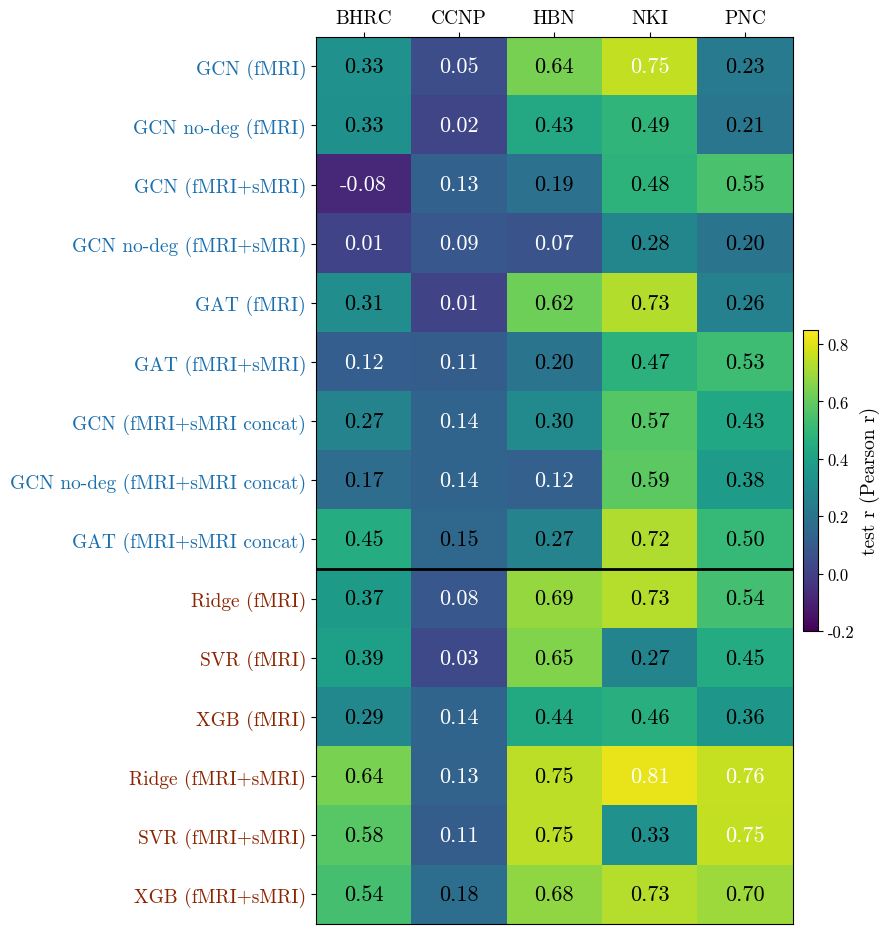

In [40]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import re as _re

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["cmr10", "STIXGeneral", "DejaVu Serif"]
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["axes.unicode_minus"] = False   # silences the cmr10 minus-sign warning

# ── Build data ────────────────────────────────────────────────────────────────
# GNN rows: mean test_r of top-5 trials (selected by best_state_val_loss) per split
# Baseline rows: test_r of single best config selected by val_r per split

def _arch_group_test(row):
    m = _re.search(r'_(gcn|gat)_(fmri|multi|concat)', row["trial_id"])
    if m is None: return "unknown"
    arch = m.group(1).upper()
    mod  = {"fmri": "fMRI", "multi": "fMRI&sMRI", "concat": "fMRI_concat_sMRI"}[m.group(2)]
    is_nodeg = any(el.startswith("nodeg") for el in row["trial_id"].split("_"))
    return f"{arch}_{mod}" + ("_nodeg" if is_nodeg and arch != "GAT" else "")

split_labels = {s: f"{s.replace('LOO_','')}" for s in LOO_SPLITS}

hm_rows = []

for group in GROUPS:
    row = {"label": group, "kind": "GNN"}
    for split in LOO_SPLITS:
        res_csv  = os.path.join(DIR, split, "test_results.csv")
        loot_csv = os.path.join(DIR, split, "results_table.csv")
        if not os.path.exists(res_csv):
            row[split] = np.nan; continue
        test_df = pd.read_csv(res_csv)
        loo_df  = pd.read_csv(loot_csv)
        loo_df["arch"] = loo_df.apply(_arch_group_test, axis=1)
        merged = loo_df.merge(test_df, on="trial_id", how="inner")
        sub = merged[merged["arch"] == group].nlargest(5, "best_val_r")
        row[split] = round(sub["test_r"].mean(), 3) if not sub.empty else np.nan
    hm_rows.append(row)

# Collect all baseline labels first so order is consistent
bl_labels_seen = []
bl_data_by_label = {}
for split in LOO_SPLITS:
    csv_path = os.path.join(DIR, "BaselineExperiments", split, "results_table.csv")
    if not os.path.exists(csv_path): continue
    bl_df = pd.read_csv(csv_path)
    bl_df = bl_df[bl_df["r_test"].notna()].copy()
    bl_df["model"]    = bl_df["name"].str.split(".").str[0]
    bl_df["modality"] = bl_df["name"].apply(lambda x: "fMRI&sMRI" if "fMRI&sMRI" in x else "fMRI")
    best = bl_df.loc[bl_df.groupby(["model","modality"])["r_val"].idxmax()]
    for _, r in best.sort_values(["modality","model"]).iterrows():
        lbl = f"{r['model']} ({r['modality']})".replace("&","&")
        if lbl not in bl_data_by_label:
            bl_data_by_label[lbl] = {"label": lbl, "kind": "Baseline"}
            bl_labels_seen.append(lbl)
        bl_data_by_label[lbl][split] = round(r["r_test"], 3)

hm_rows.extend(bl_data_by_label[lbl] for lbl in bl_labels_seen)

labels = [r["label"] for r in hm_rows]
kinds  = [r["kind"]  for r in hm_rows]
matrix = np.array([[r.get(s, np.nan) for s in LOO_SPLITS] for r in hm_rows])
col_labels = [split_labels[s] for s in LOO_SPLITS]

# ── Plot ──────────────────────────────────────────────────────────────────────
n_gnn = sum(1 for k in kinds if k == "GNN")
fig, ax = plt.subplots(figsize=(9, 0.55 * len(labels) + 1.2))

im = ax.imshow(matrix, aspect="auto", cmap="viridis", vmin=-0.2, vmax=0.85)

# Annotate cells
for i in range(len(labels)):
    for j in range(len(LOO_SPLITS)):
        val = matrix[i, j]
        if np.isnan(val):
            txt = "–"
            color = "grey"
        else:
            txt = f"{val:.2f}"
            color = "black" if 0.15 < val < 0.75 else "white"
        ax.text(j, i, txt, ha="center", va="center", fontsize=16,
                color=color, fontweight="bold")

# Separator line between GNN and Baseline sections
ax.axhline(n_gnn - 0.5, color="black", linewidth=2)

ax.set_xticks(range(len(LOO_SPLITS)))
ax.set_xticklabels(col_labels, fontsize=14, fontweight="bold")
ax.set_yticks(range(len(labels)))
def _pretty(s):
    # Baselines already arrive as "Ridge (fMRI&sMRI)" — just fix the ampersand
    if "(" in s:
        return s.replace("&", "+")
    # GNNs arrive as "GCN_fMRI", "GCN_fMRI&sMRI", "GCN_fMRI&sMRI_nodeg", "GAT_fMRI"
    nodeg = s.endswith("_nodeg")
    s = s.replace("_nodeg", "")
    arch, mod = s.split("_", 1)          # "GCN", "fMRI&sMRI"
    mod = "fMRI+sMRI concat" if mod == "fMRI_concat_sMRI" else mod.replace("&", "+")          # "fMRI+sMRI"
    suffix = " no-deg" if nodeg else ""
    return f"{arch}{suffix} ({mod})"

ax.set_yticklabels([_pretty(l) for l in labels], fontsize=14)
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

# Row colour bands
for i, kind in enumerate(kinds):
    ax.get_yticklabels()[i].set_color("#1a6faf" if kind == "GNN" else "#8b2500")

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("test r (Pearson r)", fontsize=14)# ax.set_title("test r per LOO split\n"
#              "GNN: mean of top-5 trials (selected by val loss) | "
#              "Baseline: best single config (selected by val r)",
#              fontsize=9, pad=14)
plt.tight_layout()
plt.savefig(os.path.join(DIR, FIGURES_DIR, "test_r_heatmap_R.pdf"),
            bbox_inches="tight")


plt.show()



In [41]:
# ── Same data as the heatmap above, plain table form (no color) ────────────────
heatmap_table_df = pd.DataFrame(matrix, index=labels, columns=col_labels)
heatmap_table_df.insert(0, "Model", kinds)
print("test_r per LOO split (same data as heatmap)")
display(heatmap_table_df)

test_r per LOO split (same data as heatmap)


,Model,BHRC,CCNP,HBN,NKI,PNC
GCN_fMRI,GNN,0.330,0.047,0.636,0.752,0.232
GCN_fMRI_nodeg,GNN,0.329,0.020,0.435,0.486,0.213
GCN_fMRI&sMRI,GNN,-0.077,0.126,0.192,0.479,0.550
GCN_fMRI&sMRI_nodeg,GNN,0.010,0.085,0.068,0.282,0.205
GAT_fMRI,GNN,0.313,0.014,0.620,0.730,0.261
GAT_fMRI&sMRI,GNN,0.115,0.109,0.202,0.474,0.525
GCN_fMRI_concat_sMRI,GNN,0.268,0.140,0.303,0.574,0.431
GCN_fMRI_concat_sMRI_nodeg,GNN,0.174,0.137,0.120,0.586,0.379
GAT_fMRI_concat_sMRI,GNN,0.452,0.152,0.270,0.725,0.502
Ridge (fMRI),Baseline,0.374,0.084,0.685,0.733,0.535


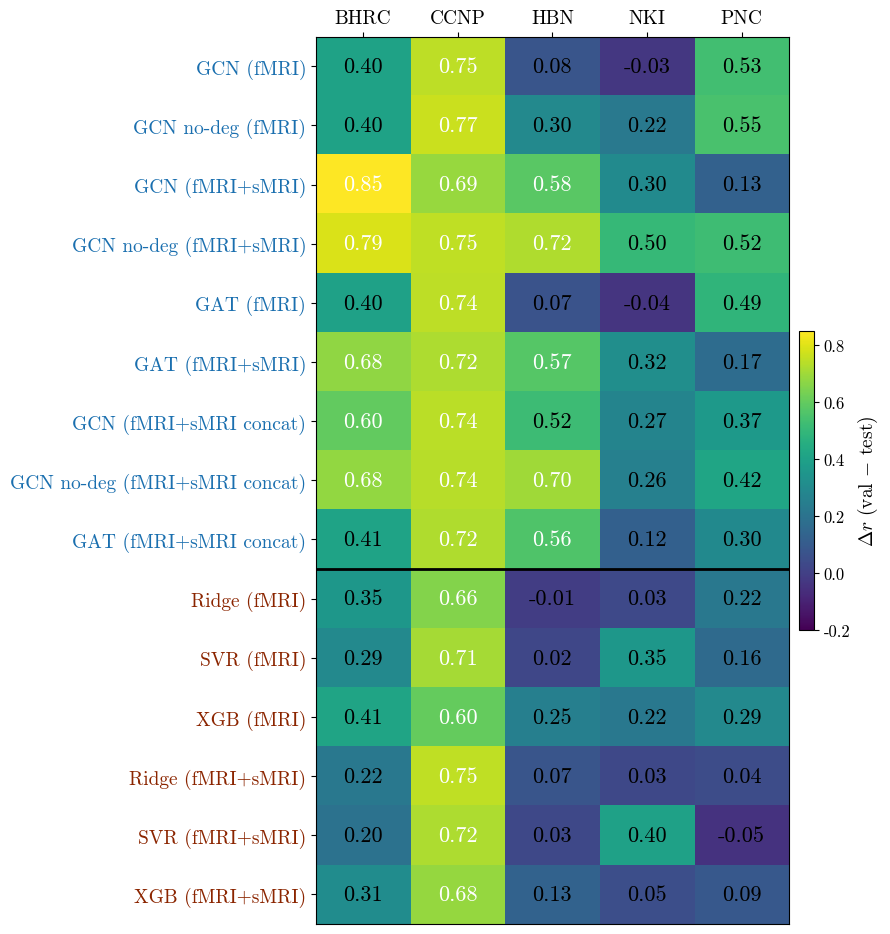

In [42]:
# ── Δr heatmap (val_r − test_r): same layout as test_r heatmap ───────────────
import matplotlib.pyplot as plt
import numpy as np
import re as _re

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["cmr10", "STIXGeneral", "DejaVu Serif"]
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["axes.unicode_minus"] = False

# ── GNN rows: mean(val_r − test_r) over top-5 per split ─────────────────────
dr_rows = []

for group in GROUPS:
    row = {"label": group, "kind": "GNN"}
    for split in LOO_SPLITS:
        res_csv  = os.path.join(DIR, split, "test_results.csv")
        loot_csv = os.path.join(DIR, split, "results_table.csv")
        if not os.path.exists(res_csv):
            row[split] = np.nan; continue
        test_df = pd.read_csv(res_csv)
        loo_df  = pd.read_csv(loot_csv)
        loo_df["arch"] = loo_df.apply(_arch_group_test, axis=1)
        merged = loo_df.merge(test_df, on="trial_id", how="inner")
        sub = merged[merged["arch"] == group].nlargest(5, "best_val_r")
        row[split] = round((sub["best_val_r"] - sub["test_r"]).mean(), 3) if not sub.empty else np.nan
    dr_rows.append(row)

# ── Baseline rows: val_r − test_r for best config per split ──────────────────
bl_labels_seen_dr = []
bl_data_by_label_dr = {}
for split in LOO_SPLITS:
    csv_path = os.path.join(DIR, "BaselineExperiments", split, "results_table.csv")
    if not os.path.exists(csv_path): continue
    bl_df = pd.read_csv(csv_path)
    bl_df = bl_df[bl_df["r_test"].notna()].copy()
    bl_df["model"]    = bl_df["name"].str.split(".").str[0]
    bl_df["modality"] = bl_df["name"].apply(lambda x: "fMRI&sMRI" if "fMRI&sMRI" in x else "fMRI")
    best = bl_df.loc[bl_df.groupby(["model", "modality"])["r_val"].idxmax()]
    for _, r in best.sort_values(["modality", "model"]).iterrows():
        lbl = f"{r['model']} ({r['modality']})".replace("&", "&")
        if lbl not in bl_data_by_label_dr:
            bl_data_by_label_dr[lbl] = {"label": lbl, "kind": "Baseline"}
            bl_labels_seen_dr.append(lbl)
        bl_data_by_label_dr[lbl][split] = round(r["r_val"] - r["r_test"], 3)

dr_rows.extend(bl_data_by_label_dr[lbl] for lbl in bl_labels_seen_dr)

labels_dr = [r["label"] for r in dr_rows]
kinds_dr  = [r["kind"]  for r in dr_rows]
matrix_dr = np.array([[r.get(s, np.nan) for s in LOO_SPLITS] for r in dr_rows])
col_labels_dr = [s.replace("LOO_", "") for s in LOO_SPLITS]

# ── Plot ──────────────────────────────────────────────────────────────────────
n_gnn_dr = sum(1 for k in kinds_dr if k == "GNN")
fig, ax = plt.subplots(figsize=(9, 0.55 * len(labels_dr) + 1.2))

im = ax.imshow(matrix_dr, aspect="auto", cmap="viridis", vmin=-0.2, vmax=0.85)

for i in range(len(labels_dr)):
    for j in range(len(LOO_SPLITS)):
        val = matrix_dr[i, j]
        if np.isnan(val):
            txt, color = "–", "grey"
        else:
            txt   = f"{val:.2f}"
            color = "black" if val < 0.55 else "white"
        ax.text(j, i, txt, ha="center", va="center", fontsize=16,
                color=color, fontweight="bold")

ax.axhline(n_gnn_dr - 0.5, color="black", linewidth=2)

ax.set_xticks(range(len(LOO_SPLITS)))
ax.set_xticklabels(col_labels_dr, fontsize=14, fontweight="bold")
ax.set_yticks(range(len(labels_dr)))
ax.set_yticklabels([_pretty(l) for l in labels_dr], fontsize=14)
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

for i, kind in enumerate(kinds_dr):
    ax.get_yticklabels()[i].set_color("#1a6faf" if kind == "GNN" else "#8b2500")

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.ax.tick_params(labelsize=12)
cbar.set_label(r"$\Delta r$ (val $-$ test)", fontsize=14)

plt.tight_layout()
plt.savefig(os.path.join(DIR, FIGURES_DIR, "delta_r_heatmap_R.pdf"), bbox_inches="tight")
plt.show()


In [43]:
# ── Same data as the heatmap above, plain table form (no color) ────────────────
heatmap_table_df = pd.DataFrame(matrix_dr, index=labels, columns=col_labels)
heatmap_table_df.insert(0, "Model", kinds)
print("test_r per LOO split (same data as heatmap)")
display(heatmap_table_df)

test_r per LOO split (same data as heatmap)


,Model,BHRC,CCNP,HBN,NKI,PNC
GCN_fMRI,GNN,0.403,0.746,0.077,-0.031,0.533
GCN_fMRI_nodeg,GNN,0.404,0.766,0.296,0.223,0.549
GCN_fMRI&sMRI,GNN,0.854,0.690,0.580,0.304,0.128
GCN_fMRI&sMRI_nodeg,GNN,0.789,0.751,0.724,0.502,0.522
GAT_fMRI,GNN,0.401,0.745,0.069,-0.036,0.488
GAT_fMRI&sMRI,GNN,0.675,0.720,0.574,0.320,0.170
GCN_fMRI_concat_sMRI,GNN,0.597,0.741,0.519,0.272,0.366
GCN_fMRI_concat_sMRI_nodeg,GNN,0.678,0.737,0.699,0.256,0.419
GAT_fMRI_concat_sMRI,GNN,0.411,0.724,0.560,0.123,0.299
Ridge (fMRI),Baseline,0.354,0.655,-0.008,0.033,0.220


In [44]:
# ── Overall ranking by mean test_r excluding CCNP ────────────────────────────
# GNN: mean test_r of top-5 trials averaged over BHRC, HBN, NKI, PNC
# Baseline: test_r of best-by-val_r config averaged over BHRC, HBN, NKI, PNC

_excl = [s for s in LOO_SPLITS if s != "LOO_CCNP"]

rank_rows = []
for r in hm_rows:
    vals = [r.get(s, float("nan")) for s in _excl]
    vals_clean = [v for v in vals if not pd.isna(v)]
    mean_excl = round(sum(vals_clean) / len(vals_clean), 3) if vals_clean else float("nan")
    rank_rows.append({
        "Model":                  r["label"],
        "Type":                   r["kind"],
        "Mean test_r (excl CCNP)": mean_excl,
        **{s: r.get(s, float("nan")) for s in LOO_SPLITS},
    })

rank_df = (pd.DataFrame(rank_rows)
             .set_index("Model")
             .sort_values("Mean test_r (excl CCNP)", ascending=False))
print("Overall ranking by mean test_r (BHRC + HBN + NKI + PNC, CCNP excluded)")
print("GNN score = mean of top-5 trials  |  Baseline score = best single config selected by val_r")
display(rank_df)


Overall ranking by mean test_r (BHRC + HBN + NKI + PNC, CCNP excluded)
GNN score = mean of top-5 trials  |  Baseline score = best single config selected by val_r


,Type,Mean test_r (excl CCNP),LOO_BHRC,LOO_CCNP,LOO_HBN,LOO_NKI,LOO_PNC
Model,,,,,,,
Ridge (fMRI&sMRI),Baseline,0.740,0.640,0.133,0.747,0.815,0.757
XGB (fMRI&sMRI),Baseline,0.661,0.541,0.180,0.675,0.732,0.698
SVR (fMRI&sMRI),Baseline,0.603,0.579,0.110,0.746,0.333,0.753
Ridge (fMRI),Baseline,0.582,0.374,0.084,0.685,0.733,0.535
GCN_fMRI,GNN,0.488,0.330,0.047,0.636,0.752,0.232
GAT_fMRI_concat_sMRI,GNN,0.487,0.452,0.152,0.270,0.725,0.502
GAT_fMRI,GNN,0.481,0.313,0.014,0.620,0.730,0.261
SVR (fMRI),Baseline,0.441,0.394,0.031,0.652,0.273,0.445
GCN_fMRI_concat_sMRI,GNN,0.394,0.268,0.140,0.303,0.574,0.431


In [45]:
# ── Summary table: mean across BHRC, HBN, NKI, PNC (CCNP excluded) ──────────

_splits_excl = [s for s in LOO_SPLITS if s != "LOO_CCNP"]

summary_rows = []

# GNN rows: collect all 20 values (top-5 × 4 splits), mean ± std over 20
for group in GROUPS:
    val_rs, val_maes, test_rs, test_maes, delta_rs, delta_maes = [], [], [], [], [], []
    for split in _splits_excl:
        df = top_k[split][group].dropna(subset=["test_r", "test_mae"])
        val_rs.extend(df["best_val_r"].tolist())
        val_maes.extend(df["best_val_mae"].tolist())
        test_rs.extend(df["test_r"].tolist())
        test_maes.extend(df["test_mae"].tolist())
        delta_rs.extend((df["best_val_r"] - df["test_r"]).tolist())
        delta_maes.extend((df["test_mae"] - df["best_val_mae"]).tolist())

    def ms(a): return np.mean(a), np.std(a)
    if not test_rs:   # no tested trials for this group yet
        continue
    mvr,   svr   = ms(val_rs)
    mvmae, svmae = ms(val_maes)
    mtr,   str_  = ms(test_rs)
    mtmae, stmae = ms(test_maes)
    mdr,   sdr   = ms(delta_rs)
    mdmae, sdmae = ms(delta_maes)

    summary_rows.append({
        "Kind":     "GNN",
        "Model":    group,
        "Val r":    f"{mvr:.3f} ± {svr:.3f}",
        "Val MAE":  f"{mvmae:.2f} ± {svmae:.2f}",
        "Test r":   f"{mtr:.3f} ± {str_:.3f}",
        "Test MAE": f"{mtmae:.2f} ± {stmae:.2f}",
        "Δr":       f"{mdr:.3f} ± {sdr:.3f}",
        "ΔMAE":     f"{mdmae:.2f} ± {sdmae:.2f}",
        "_sort":    mtr,
    })

# Baseline rows: best-by-val_r config per split → mean ± std over 4 splits
bl_accum = {}
for split in _splits_excl:
    for label, v in _load_best_baselines(split).items():
        if label not in bl_accum:
            bl_accum[label] = {"val_r": [], "val_mae": [], "test_r": [], "test_mae": [],
                               "delta_r": [], "delta_mae": []}
        bl_accum[label]["val_r"].append(v["val_r"])
        bl_accum[label]["val_mae"].append(v["val_mae"])
        bl_accum[label]["test_r"].append(v["test_r"])
        bl_accum[label]["test_mae"].append(v["test_mae"])
        bl_accum[label]["delta_r"].append(v["val_r"] - v["test_r"])
        bl_accum[label]["delta_mae"].append(v["test_mae"] - v["val_mae"])

for label, vals in bl_accum.items():
    mvr,   svr   = ms(vals["val_r"])
    mvmae, svmae = ms(vals["val_mae"])
    mtr,   str_  = ms(vals["test_r"])
    mtmae, stmae = ms(vals["test_mae"])
    mdr,   sdr   = ms(vals["delta_r"])
    mdmae, sdmae = ms(vals["delta_mae"])
    summary_rows.append({
        "Kind":     "Baseline",
        "Model":    label,
        "Val r":    f"{mvr:.3f} ± {svr:.3f}",
        "Val MAE":  f"{mvmae:.2f} ± {svmae:.2f}",
        "Test r":   f"{mtr:.3f} ± {str_:.3f}",
        "Test MAE": f"{mtmae:.2f} ± {stmae:.2f}",
        "Δr":       f"{mdr:.3f} ± {sdr:.3f}",
        "ΔMAE":     f"{mdmae:.2f} ± {sdmae:.2f}",
        "_sort":    mtr,
    })

summary_df = (pd.DataFrame(summary_rows)
                .sort_values("_sort", ascending=False)
                .drop(columns="_sort")
                .set_index(["Kind", "Model"]))

print("Summary: mean across BHRC + HBN + NKI + PNC (CCNP excluded)")
print("GNN = mean ± std over 20 trials (top-5 × 4 splits) | Baseline = mean ± std over 4 splits (best config by val_r)")
display(summary_df)


Summary: mean across BHRC + HBN + NKI + PNC (CCNP excluded)
GNN = mean ± std over 20 trials (top-5 × 4 splits) | Baseline = mean ± std over 4 splits (best config by val_r)


Val r      Val MAE  \
Kind     Model                                                    
Baseline Ridge (fMRI&sMRI)           0.831 ± 0.022  1.64 ± 0.07   
         XGB (fMRI&sMRI)             0.807 ± 0.027  1.77 ± 0.10   
         SVR (fMRI&sMRI)             0.747 ± 0.028  2.00 ± 0.07   
         Ridge (fMRI)                0.732 ± 0.034  2.10 ± 0.16   
GNN      GCN_fMRI                    0.733 ± 0.021  2.06 ± 0.20   
         GAT_fMRI_concat_sMRI        0.836 ± 0.024  1.64 ± 0.07   
         GAT_fMRI                    0.712 ± 0.024  2.14 ± 0.20   
Baseline SVR (fMRI)                  0.649 ± 0.033  2.36 ± 0.08   
GNN      GCN_fMRI_concat_sMRI        0.833 ± 0.026  1.64 ± 0.09   
Baseline XGB (fMRI)                  0.681 ± 0.020  2.27 ± 0.08   
GNN      GCN_fMRI_nodeg              0.734 ± 0.019  2.02 ± 0.18   
         GAT_fMRI&sMRI               0.764 ± 0.040  1.91 ± 0.06   
         GCN_fMRI_concat_sMRI_nodeg  0.828 ± 0.022  1.68 ± 0.07   
         GCN_fMRI&sMRI               0.753 ± 0.043  1.94 ± 0.04   
         GCN_fMRI&sMRI_nodeg         0.775 ± 0.029  1.89 ± 0.04   

                                            Test r     Test MAE  \
Kind     Model                                                    
Baseline Ridge (fMRI&sMRI)           0.740 ± 0.063  2.18 ± 0.37   
         XGB (fMRI&sMRI)             0.661 ± 0.072  2.92 ± 0.65   
         SVR (fMRI&sMRI)             0.603 ± 0.171  3.07 ± 1.02   
         Ridge (fMRI)                0.582 ± 0.140  5.18 ± 2.12   
GNN      GCN_fMRI                    0.488 ± 0.223  3.11 ± 1.20   
         GAT_fMRI_concat_sMRI        0.487 ± 0.181  3.76 ± 0.98   
         GAT_fMRI                    0.481 ± 0.203  3.33 ± 1.17   
Baseline SVR (fMRI)                  0.441 ± 0.137  3.54 ± 0.80   
GNN      GCN_fMRI_concat_sMRI        0.394 ± 0.165  3.16 ± 0.95   
Baseline XGB (fMRI)                  0.386 ± 0.067  3.33 ± 0.93   
GNN      GCN_fMRI_nodeg              0.366 ± 0.209  4.23 ± 1.60   
         GAT_fMRI&sMRI               0.329 ± 0.190  3.81 ± 1.32   
         GCN_fMRI_concat_sMRI_nodeg  0.315 ± 0.226  4.03 ± 1.15   
         GCN_fMRI&sMRI               0.286 ± 0.259  3.25 ± 1.06   
         GCN_fMRI&sMRI_nodeg         0.141 ± 0.178  3.68 ± 1.27   

                                                Δr         ΔMAE  
Kind     Model                                                   
Baseline Ridge (fMRI&sMRI)           0.091 ± 0.076  0.54 ± 0.41  
         XGB (fMRI&sMRI)             0.145 ± 0.099  1.16 ± 0.72  
         SVR (fMRI&sMRI)             0.144 ± 0.172  1.07 ± 1.00  
         Ridge (fMRI)                0.150 ± 0.146  3.08 ± 2.21  
GNN      GCN_fMRI                    0.246 ± 0.240  1.05 ± 1.36  
         GAT_fMRI_concat_sMRI        0.348 ± 0.179  2.12 ± 0.95  
         GAT_fMRI                    0.231 ± 0.223  1.19 ± 1.31  
Baseline SVR (fMRI)                  0.208 ± 0.128  1.18 ± 0.86  
GNN      GCN_fMRI_concat_sMRI        0.439 ± 0.170  1.52 ± 0.95  
Baseline XGB (fMRI)                  0.295 ± 0.072  1.06 ± 0.99  
GNN      GCN_fMRI_nodeg              0.368 ± 0.218  2.21 ± 1.63  
         GAT_fMRI&sMRI               0.435 ± 0.214  1.90 ± 1.34  
         GCN_fMRI_concat_sMRI_nodeg  0.513 ± 0.228  2.35 ± 1.14  
         GCN_fMRI&sMRI               0.466 ± 0.285  1.31 ± 1.07  
         GCN_fMRI&sMRI_nodeg         0.634 ± 0.190  1.79 ± 1.26

In [46]:
# ── Summary table over ALL FIVE splits (CCNP included) ───────────────────────

def _fmt(a, nd):
    return f"{np.mean(a):.{nd}f} ± {np.std(a):.{nd}f}"


def build_summary(splits):
    rows = []
    for group in GROUPS:
        c = {"vr": [], "vmae": [], "tr": [], "tmae": [], "dr": [], "dmae": []}
        for split in splits:
            df = top_k[split][group].dropna(subset=["test_r", "test_mae"])
            c["vr"]   += df["best_val_r"].tolist()
            c["vmae"] += df["best_val_mae"].tolist()
            c["tr"]   += df["test_r"].tolist()
            c["tmae"] += df["test_mae"].tolist()
            c["dr"]   += (df["best_val_r"] - df["test_r"]).tolist()
            c["dmae"] += (df["test_mae"] - df["best_val_mae"]).tolist()
        if not c["tr"]:   # no tested trials for this group yet
            continue
        rows.append(("GNN", group, c))

    bl = {}
    for split in splits:
        for label, v in _load_best_baselines(split).items():
            c = bl.setdefault(label, {"vr": [], "vmae": [], "tr": [], "tmae": [], "dr": [], "dmae": []})
            c["vr"].append(v["val_r"]);     c["vmae"].append(v["val_mae"])
            c["tr"].append(v["test_r"]);    c["tmae"].append(v["test_mae"])
            c["dr"].append(v["val_r"] - v["test_r"])
            c["dmae"].append(v["test_mae"] - v["val_mae"])
    rows += [("Baseline", label, c) for label, c in bl.items()]

    out = pd.DataFrame([{
        "Kind": kind, "Model": model,
        "Val r":    _fmt(c["vr"], 3),   "Val MAE":  _fmt(c["vmae"], 2),
        "Test r":   _fmt(c["tr"], 3),   "Test MAE": _fmt(c["tmae"], 2),
        "Δr":       _fmt(c["dr"], 3),   "ΔMAE":     _fmt(c["dmae"], 2),
        "_sort":    np.mean(c["tr"]),
    } for kind, model, c in rows])
    return out.sort_values("_sort", ascending=False).drop(columns="_sort").set_index(["Kind", "Model"])


print("Summary: mean across all five splits (CCNP included)")
print("GNN = mean ± std over 25 trials (top-5 × 5 splits) | Baseline = mean ± std over 5 splits (best config by val_r)")
display(build_summary(list(LOO_SPLITS)))

Summary: mean across all five splits (CCNP included)
GNN = mean ± std over 25 trials (top-5 × 5 splits) | Baseline = mean ± std over 5 splits (best config by val_r)


Val r      Val MAE  \
Kind     Model                                                    
Baseline Ridge (fMRI&sMRI)           0.841 ± 0.029  1.63 ± 0.06   
         XGB (fMRI&sMRI)             0.818 ± 0.033  1.74 ± 0.10   
         SVR (fMRI&sMRI)             0.763 ± 0.041  1.98 ± 0.08   
         Ridge (fMRI)                0.733 ± 0.031  2.11 ± 0.15   
GNN      GAT_fMRI_concat_sMRI        0.844 ± 0.027  1.61 ± 0.09   
         GCN_fMRI                    0.745 ± 0.031  2.04 ± 0.19   
         GAT_fMRI                    0.721 ± 0.029  2.13 ± 0.19   
Baseline SVR (fMRI)                  0.667 ± 0.046  2.35 ± 0.07   
GNN      GCN_fMRI_concat_sMRI        0.842 ± 0.030  1.61 ± 0.10   
Baseline XGB (fMRI)                  0.693 ± 0.030  2.27 ± 0.07   
GNN      GCN_fMRI_nodeg              0.744 ± 0.027  2.01 ± 0.16   
         GAT_fMRI&sMRI               0.777 ± 0.045  1.88 ± 0.09   
         GCN_fMRI_concat_sMRI_nodeg  0.837 ± 0.027  1.65 ± 0.09   
         GCN_fMRI&sMRI               0.765 ± 0.046  1.91 ± 0.07   
         GCN_fMRI&sMRI_nodeg         0.787 ± 0.036  1.86 ± 0.08   

                                            Test r     Test MAE  \
Kind     Model                                                    
Baseline Ridge (fMRI&sMRI)           0.618 ± 0.249  2.43 ± 0.60   
         XGB (fMRI&sMRI)             0.565 ± 0.203  2.96 ± 0.59   
         SVR (fMRI&sMRI)             0.504 ± 0.249  3.10 ± 0.91   
         Ridge (fMRI)                0.482 ± 0.235  4.76 ± 2.07   
GNN      GAT_fMRI_concat_sMRI        0.420 ± 0.210  3.63 ± 0.91   
         GCN_fMRI                    0.400 ± 0.267  3.07 ± 1.07   
         GAT_fMRI                    0.388 ± 0.261  3.28 ± 1.05   
Baseline SVR (fMRI)                  0.359 ± 0.205  3.40 ± 0.77   
GNN      GCN_fMRI_concat_sMRI        0.343 ± 0.180  3.12 ± 0.85   
Baseline XGB (fMRI)                  0.337 ± 0.116  3.22 ± 0.86   
GNN      GCN_fMRI_nodeg              0.297 ± 0.233  3.98 ± 1.51   
         GAT_fMRI&sMRI               0.285 ± 0.193  3.76 ± 1.19   
         GCN_fMRI_concat_sMRI_nodeg  0.279 ± 0.216  3.79 ± 1.14   
         GCN_fMRI&sMRI               0.254 ± 0.241  3.17 ± 0.96   
         GCN_fMRI&sMRI_nodeg         0.130 ± 0.161  3.51 ± 1.19   

                                                Δr         ΔMAE  
Kind     Model                                                   
Baseline Ridge (fMRI&sMRI)           0.223 ± 0.273  0.81 ± 0.64  
         XGB (fMRI&sMRI)             0.253 ± 0.233  1.22 ± 0.65  
         SVR (fMRI&sMRI)             0.259 ± 0.277  1.13 ± 0.90  
         Ridge (fMRI)                0.251 ± 0.241  2.65 ± 2.15  
GNN      GAT_fMRI_concat_sMRI        0.424 ± 0.219  2.02 ± 0.87  
         GCN_fMRI                    0.346 ± 0.294  1.03 ± 1.21  
         GAT_fMRI                    0.334 ± 0.287  1.15 ± 1.18  
Baseline SVR (fMRI)                  0.308 ± 0.230  1.05 ± 0.81  
GNN      GCN_fMRI_concat_sMRI        0.499 ± 0.195  1.51 ± 0.85  
Baseline XGB (fMRI)                  0.357 ± 0.139  0.95 ± 0.91  
GNN      GCN_fMRI_nodeg              0.448 ± 0.252  1.98 ± 1.52  
         GAT_fMRI&sMRI               0.492 ± 0.224  1.88 ± 1.21  
         GCN_fMRI_concat_sMRI_nodeg  0.558 ± 0.224  2.14 ± 1.10  
         GCN_fMRI&sMRI               0.511 ± 0.271  1.26 ± 0.97  
         GCN_fMRI&sMRI_nodeg         0.657 ± 0.177  1.65 ± 1.16

## How the paper's claims change under validation-r selection (and with five splits)

**What changed.** The GNN trials (top five per architecture per split) are now ranked by highest validation Pearson r instead of lowest validation MSE. Baselines are unchanged (one configuration per split, chosen by validation r), so GNNs and baselines now use the same selection metric. "Paper" below means the submitted Table 1: validation-MSE selection, four non-CCNP splits. Between 17 and 24 of the 30 top-five slots per split are the same trials under both rules. Group-level mean test r moves by at most 0.031 (four splits), and no split × architecture cell moves by more than 0.081 (GAT fMRI on HBN). The order of the 12 models by test r is identical to Table 1 in both the four-split and the five-split table.

### A. Four non-CCNP splits (the paper's table): GNN rows, validation MSE → validation r
Baseline rows are identical to Table 1.

| Model | Test r | Test MAE | Δr | ΔMAE |
|---|---|---|---|---|
| GCN (fMRI) | 0.495 → 0.488 | 3.17 → 3.11 | 0.234 → 0.246 | 1.14 → 1.05 |
| GAT (fMRI) | 0.450 → 0.481 | 3.57 → 3.33 | 0.255 → 0.231 | 1.46 → 1.19 |
| GCN no-deg (fMRI) | 0.378 → 0.366 | 4.11 → 4.23 | 0.353 → 0.368 | 2.08 → 2.21 |
| GCN (fMRI+sMRI) | 0.287 → 0.286 | 3.24 → 3.25 | 0.465 → 0.466 | 1.30 → 1.31 |
| GAT (fMRI+sMRI) | 0.326 → 0.329 | 3.73 → 3.81 | 0.437 → 0.435 | 1.83 → 1.90 |
| GCN no-deg (fMRI+sMRI) | 0.154 → 0.141 | 3.48 → 3.68 | 0.621 → 0.634 | 1.59 → 1.79 |

Validation r (validation-r selection): GCN 0.733, GAT 0.712, GCN no-deg 0.734, GCN+sMRI 0.753, GAT+sMRI 0.764, GCN no-deg+sMRI 0.775 (Ridge fMRI: 0.732).

### B. All five splits (GNNs selected by validation r; means; the table above in this notebook has the ± values)

| Model | Val r | Test r | Test MAE | Δr | ΔMAE |
|---|---|---|---|---|---|
| Ridge (fMRI+sMRI) | 0.841 | 0.618 | 2.43 | 0.223 | 0.81 |
| XGB (fMRI+sMRI) | 0.818 | 0.565 | 2.96 | 0.253 | 1.22 |
| SVR (fMRI+sMRI) | 0.763 | 0.504 | 3.10 | 0.259 | 1.13 |
| Ridge (fMRI) | 0.733 | 0.482 | 4.76 | 0.251 | 2.65 |
| GCN (fMRI) | 0.745 | 0.400 | 3.07 | 0.346 | 1.03 |
| GAT (fMRI) | 0.721 | 0.388 | 3.28 | 0.334 | 1.15 |
| SVR (fMRI) | 0.667 | 0.359 | 3.40 | 0.308 | 1.05 |
| XGB (fMRI) | 0.693 | 0.337 | 3.22 | 0.357 | 0.95 |
| GCN no-deg (fMRI) | 0.744 | 0.297 | 3.98 | 0.448 | 1.98 |
| GAT (fMRI+sMRI) | 0.777 | 0.285 | 3.76 | 0.492 | 1.88 |
| GCN (fMRI+sMRI) | 0.765 | 0.254 | 3.17 | 0.511 | 1.26 |
| GCN no-deg (fMRI+sMRI) | 0.787 | 0.130 | 3.51 | 0.657 | 1.65 |

With validation-MSE selection, the five-split test r of the GNNs would be GCN 0.404, GAT 0.363, GCN no-deg 0.307, GCN+sMRI 0.254, GAT+sMRI 0.281, GCN no-deg+sMRI 0.140.

### Claims that hold under validation-r selection, in both the four-split and five-split tables
1. **Ridge (fMRI) beats both fMRI-only GNNs on test r.** Four splits: 0.582 vs 0.488 (GCN) and 0.481 (GAT). Five splits: 0.482 vs 0.400 and 0.388.
2. **Ridge (fMRI) has the highest test MAE of all models** (5.18 four splits, 4.76 five splits), so the metric contradiction in Section 6.4 stands.
3. **SVR and XGBoost (fMRI) stay below the fMRI-only GNNs on test r** (four splits 0.441 and 0.386; five splits 0.359 and 0.337) and remain competitive on test MAE (five splits: XGB 3.22 vs GAT 3.28, GCN 3.07).
4. **Degree normalization.** The degree-normalized GCN beats its no-deg counterpart on test r, test MAE, Δr and ΔMAE in both modalities (five splits: fMRI 0.400 vs 0.297; fMRI+sMRI 0.254 vs 0.130).
5. **sMRI fusion is asymmetric.** Baselines gain on test r and test MAE (five splits: Ridge 0.482 → 0.618, SVR 0.359 → 0.504, XGB 0.337 → 0.565); the GNNs lose test r (GCN 0.400 → 0.254, GAT 0.388 → 0.285, no-deg 0.297 → 0.130) and their Δr widens (GCN 0.346 → 0.511, GAT 0.334 → 0.492, no-deg 0.448 → 0.657), while the baselines' Δr narrows (Ridge 0.251 → 0.223, SVR 0.308 → 0.259, XGB 0.357 → 0.253). Validation r and MAE improve for every model with sMRI. Test MAE: GCN 3.07 → 3.17, GAT 3.28 → 3.76, no-deg 3.98 → 3.51 (the only GNN that improves).
6. **Per-split statements.** CCNP is a universal failure (best test r is 0.18, XGB fMRI+sMRI; best GNN 0.126). The multimodal GCN reaches -0.077 on BHRC, its lowest split. The largest fMRI → multimodal drop is on HBN (GCN 0.636 → 0.192, GAT 0.620 → 0.202). PNC shows a gain (GCN 0.232 → 0.550, GAT 0.261 → 0.525). Outside CCNP, no multimodal GNN beats any multimodal baseline except SVR on NKI (GCN 0.479 and GAT 0.474 vs SVR 0.333).

### Claims or numbers that change
1. **"Ridge (fMRI) is better than the fMRI-only GCN and GAT on validation r" no longer holds.** Selecting GNNs by validation r raises their validation r. Four splits: Ridge 0.732 vs GCN 0.733 and GAT 0.712 (paper: 0.732 vs 0.729 and 0.706). Five splits: Ridge 0.733 vs GCN 0.745 and GAT 0.721; the GCN is above Ridge even with validation-MSE selection (0.742). Suggested wording: comparable validation r, clearly higher test r for Ridge.
2. **Abstract numbers.** Four splits: Ridge 0.582 vs GCN 0.488 and GAT 0.481 (paper: 0.495 and 0.450). Five splits: Ridge 0.482 vs GCN 0.400 and GAT 0.388 (validation-MSE selection: 0.404 and 0.363). The GAT-GCN gap narrows from 0.045 to 0.007 (four splits).
3. **"No-deg outperformed on both validation metrics by small margins."** For fMRI-only, validation r is essentially tied (four splits 0.734 vs 0.733; five splits 0.744 vs 0.745); no-deg is better on validation MAE (2.02 vs 2.06; 2.01 vs 2.04). For fMRI+sMRI, no-deg is better on both (0.775 vs 0.753; 1.89 vs 1.94).
4. **ΔMAE under fusion.** "The GCN held its ΔMAE": 1.05 → 1.31 (four splits) and 1.03 → 1.26 (five splits), roughly +0.25 against a spread of about ±1.2 to ±1.4. Baselines: "SVR and XGBoost essentially unchanged" is looser with five splits (SVR 1.05 → 1.13, XGB 0.95 → 1.22).
5. **"Baselines repeatedly outperform the GNNs in both gap metrics."** Holds clearly for Δr. For ΔMAE the fMRI-only GCN and GAT (1.03 and 1.15 in five splits) are inside the range of SVR and XGB (0.95 to 1.22); only multimodal Ridge (0.81) is clearly lower, and fMRI Ridge (2.65) is higher. Under validation-r selection the fMRI-only GNNs' ΔMAE is a little lower than under validation-MSE selection (four splits GCN 1.14 → 1.05, GAT 1.46 → 1.19).
6. **Five-split wording of the per-split statements.** "PNC was the only split where fusion improved test r for both GCN and GAT" no longer holds: CCNP also improves for both (GCN 0.047 → 0.126, GAT 0.014 → 0.109), from a near-zero base. "No multimodal GNN beats a multimodal baseline except SVR on NKI" gets a second exception on CCNP: multimodal GCN 0.126 beats multimodal SVR 0.110. "Fusion predominantly degraded OOD generalization, though not universally" should name both PNC and CCNP.
7. **"Followed by multimodal XGBoost" (best gap metrics)** is loose independent of selection. Four splits: Δr is 0.144 for SVR+sMRI and 0.145 for XGB+sMRI; ΔMAE is lower for XGB fMRI (1.06) and SVR+sMRI (1.07) than for XGB+sMRI (1.16). Five splits: Ridge (fMRI) is second on Δr (0.251 vs 0.253 for XGB+sMRI).
8. **Selection protocol (Section 5, Figure 1 caption, Table 1 caption).** Both GNNs and baselines are now selected by validation Pearson r. One difference remains: GNNs are the mean of the top five trials, baselines are one configuration per split.

### Still to do
The baselines have not yet been rerun with selection by validation MSE, so the matched validation-MSE table (both GNNs and baselines selected by validation MSE) is not available yet.